<center><h1>Enriquez_Scott_HW3</h1></center>
<br>
<br>

Name: Scott Enriquez
<br>
GitHub Username: scottenriquez
<br>

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [1]:
%pip install -q bootstrapped==0.0.2 matplotlib==3.11.2 numpy==2.5.3 "pandas[output-formatting]==3.0.6" scikit-learn==1.9.1 seaborn==0.13.2 statsmodels==0.15.0

Note: you may need to restart the kernel to use updated packages.


In [2]:
import bootstrapped.bootstrap as bs
import bootstrapped.stats_functions as bs_stats
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
import seaborn as sns

Get the AReM Data Set

In [3]:
arem_columns = ['time', 'avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
bending1_dataset_csv_count = len(list(Path('AReM/bending1').glob('*.csv')))
bending2_dataset_csv_count = len(list(Path('AReM/bending2').glob('*.csv')))
cycling_dataset_csv_count = len(list(Path('AReM/cycling').glob('*.csv')))
lying_dataset_csv_count = len(list(Path('AReM/lying').glob('*.csv')))
sitting_dataset_csv_count = len(list(Path('AReM/sitting').glob('*.csv')))
standing_dataset_csv_count = len(list(Path('AReM/standing').glob('*.csv')))
walking_dataset_csv_count = len(list(Path('AReM/walking').glob('*.csv')))

### (b) Test and Train Data

In [4]:
# Claude Sonnet 5.5 used to generate the separator regular expression
# Prompt: In Pandas, is it possible to have a separator that supports both comma-delimited and space-delimited values in the same `pd.read_csv` statement?
def read_activity_dataset_csv_file(activity: str, dataset_index: int, is_training_data: bool) -> pd.DataFrame:
    activity_dataset = pd.read_csv(f'AReM/{activity}/dataset{dataset_index}.csv', engine='python', comment='#',
                                   names=arem_columns, sep=r'[,\s]+', usecols=range(7))
    activity_dataset['instance'] = f'{activity}_{dataset_index}'
    activity_dataset['activity'] = ''.join([character for character in activity if not character.isdigit()])
    activity_dataset['is_training_data'] = is_training_data
    return activity_dataset

In [5]:
test_data = pd.concat(
    [read_activity_dataset_csv_file(activity, index, is_training_data=False) for activity in ['bending1', 'bending2']
     for index in
     range(1, 3)] +
    [read_activity_dataset_csv_file(activity, index, is_training_data=False) for activity in
     ['cycling', 'lying', 'sitting', 'standing', 'walking'] for index in range(1, 4)],
    ignore_index=True
)
display(test_data)

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,instance,activity,is_training_data
0,0,39.25,0.43,22.75,0.43,33.75,1.30,bending1_1,bending,False
1,250,39.25,0.43,23.00,0.00,33.00,0.00,bending1_1,bending,False
2,500,39.25,0.43,23.25,0.43,33.00,0.00,bending1_1,bending,False
3,750,39.50,0.50,23.00,0.71,33.00,0.00,bending1_1,bending,False
4,1000,39.50,0.50,24.00,0.00,33.00,0.00,bending1_1,bending,False
...,...,...,...,...,...,...,...,...,...,...
9115,118750,36.00,2.45,17.00,5.10,20.50,0.87,walking_3,walking,False
9116,119000,34.33,1.89,15.00,2.45,17.00,2.12,walking_3,walking,False
9117,119250,33.00,7.35,14.60,3.14,13.00,5.70,walking_3,walking,False
9118,119500,31.67,1.25,11.00,6.16,19.25,2.17,walking_3,walking,False


In [6]:
training_data = pd.concat(
    [read_activity_dataset_csv_file('bending1', index, is_training_data=True) for index in
     range(3, bending1_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('bending2', index, is_training_data=True) for index in
     range(3, bending2_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('cycling', index, is_training_data=True) for index in
     range(4, cycling_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('lying', index, is_training_data=True) for index in
     range(4, lying_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('sitting', index, is_training_data=True) for index in
     range(4, sitting_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('standing', index, is_training_data=True) for index in
     range(4, standing_dataset_csv_count + 1)] +
    [read_activity_dataset_csv_file('walking', index, is_training_data=True) for index in
     range(4, walking_dataset_csv_count + 1)],
    ignore_index=True
)
display(training_data)

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,instance,activity,is_training_data
0,0,42.00,0.71,21.25,0.43,30.00,0.00,bending1_3,bending,True
1,250,41.50,0.50,20.25,1.48,31.25,1.09,bending1_3,bending,True
2,500,41.50,0.50,14.25,1.92,33.00,0.00,bending1_3,bending,True
3,750,40.75,0.83,15.75,0.43,33.00,0.00,bending1_3,bending,True
4,1000,40.00,0.71,20.00,2.74,32.75,0.43,bending1_3,bending,True
...,...,...,...,...,...,...,...,...,...,...
33114,118750,34.50,6.18,9.00,3.56,12.67,4.19,walking_15,walking,True
33115,119000,25.75,6.02,13.75,2.05,16.00,1.58,walking_15,walking,True
33116,119250,31.50,3.35,10.25,5.12,16.25,2.95,walking_15,walking,True
33117,119500,33.75,2.77,14.00,3.24,13.75,0.43,walking_15,walking,True


### (c) Feature Extraction

#### i. Research

##### Example Time-Domain Features
- Mean
- Maximum
- Minimum
- Median
- First and third quartiles
- Standard deviation
- Skewness
- Kurtosis
- Root mean square
- Shannon entropy
- Energy
- Autocorrelation

Sources:
- https://tsfel.readthedocs.io/en/latest/descriptions/feature_list.html
- https://www.geeksforgeeks.org/data-analysis/feature-engineering-for-time-series-data-methods-and-applications/

#### ii. Extraction

In [7]:
def extract_features(data: pd.DataFrame) -> pd.DataFrame:
    instance_index = 1
    aggregated_instances = []
    feature_columns = [column for column in data.columns if
                       column not in ['time', 'instance', 'activity', 'is_training_data']]
    for instance, instance_data in data.groupby('instance'):
        aggregated_instance = {'instance_index': instance_index, 'instance': instance}
        for feature in feature_columns:
            aggregated_instance[f'minimum_{feature}'] = instance_data[feature].min()
            aggregated_instance[f'maximum_{feature}'] = instance_data[feature].max()
            aggregated_instance[f'mean_{feature}'] = instance_data[feature].mean()
            aggregated_instance[f'median_{feature}'] = instance_data[feature].median()
            aggregated_instance[f'standard_deviation_{feature}'] = instance_data[feature].std()
            first_quartile, third_quartile = instance_data[feature].quantile([0.25, 0.75])
            aggregated_instance[f'first_quartile_{feature}'] = first_quartile
            aggregated_instance[f'third_quartile_{feature}'] = third_quartile
        aggregated_instance['is_training_data'] = instance_data['is_training_data'].iloc[0]
        aggregated_instance['activity'] = instance_data['activity'].iloc[0]
        aggregated_instances.append(aggregated_instance)
        instance_index += 1
    return pd.DataFrame(aggregated_instances).set_index('instance_index')


extracted_features_data = extract_features(pd.concat([training_data, test_data], ignore_index=True))
display(extracted_features_data)

,instance,minimum_avg_rss12,maximum_avg_rss12,mean_avg_rss12,median_avg_rss12,standard_deviation_avg_rss12,first_quartile_avg_rss12,third_quartile_avg_rss12,minimum_var_rss12,maximum_var_rss12,...,third_quartile_avg_rss23,minimum_var_rss23,maximum_var_rss23,mean_var_rss23,median_var_rss23,standard_deviation_var_rss23,first_quartile_var_rss23,third_quartile_var_rss23,is_training_data,activity
instance_index,,,,,,,,,,,,,,,,,,,,,
1,bending1_1,37.25,45.00,40.624792,40.500,1.476967,39.25,42.0000,0.0,1.30,...,36.00,0.0,1.92,0.570583,0.430,0.582915,0.00,1.3000,False,bending
2,bending1_2,38.00,45.67,42.812812,42.500,1.435550,42.00,43.6700,0.0,1.22,...,34.50,0.0,3.11,0.571083,0.430,0.601010,0.00,1.3000,False,bending
3,bending1_3,35.00,47.40,43.954500,44.330,1.558835,43.00,45.0000,0.0,1.70,...,36.50,0.0,1.79,0.493292,0.430,0.513506,0.00,0.9400,True,bending
4,bending1_4,33.00,47.75,42.179812,43.500,3.670666,39.15,45.0000,0.0,3.00,...,36.33,0.0,2.18,0.613521,0.500,0.524317,0.00,1.0000,True,bending
5,bending1_5,33.00,45.75,41.678063,41.750,2.243490,41.33,42.7500,0.0,2.83,...,31.25,0.0,1.79,0.383292,0.430,0.389164,0.00,0.5000,True,bending
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
84,walking_5,20.75,46.25,34.763333,35.290,4.742208,31.67,38.2500,0.0,12.68,...,18.33,0.0,9.39,3.288271,3.270,1.647528,2.05,4.3050,True,walking
85,walking_6,21.50,51.00,34.935812,35.500,4.645944,32.00,38.0625,0.0,12.21,...,18.25,0.0,10.21,3.280021,3.015,1.700918,2.12,4.5000,True,walking
86,walking_7,18.33,47.67,34.333042,34.750,4.948770,31.25,38.0000,0.0,12.48,...,18.00,0.0,8.01,3.261583,2.980,1.617290,2.05,4.3200,True,walking


#### iii. Standard Deviation

In [8]:
def build_bootstrap_confidence_interval(data: pd.DataFrame, alpha=0.1) -> pd.DataFrame:
    extracted_feature_columns = [column for column in data.columns if
                                 column not in ['instance_index', 'instance', 'is_training_data', 'activity']]
    bootstrap_confidence_intervals = []
    for column in extracted_feature_columns:
        result = bs.bootstrap(data[column].values, stat_func=bs_stats.std, alpha=alpha)
        bootstrap_confidence_intervals.append(
            {'feature': column, 'standard_deviation': result.value, 'lower_bound': result.lower_bound,
             'upper_bound': result.upper_bound})
    return pd.DataFrame(bootstrap_confidence_intervals).set_index('feature')


display(build_bootstrap_confidence_interval(extracted_features_data))

,standard_deviation,lower_bound,upper_bound
feature,,,
minimum_avg_rss12,9.515445,8.309937,10.818754
maximum_avg_rss12,4.369322,3.477468,5.422271
mean_avg_rss12,5.305314,4.764580,5.932564
median_avg_rss12,5.409056,4.847117,6.056601
standard_deviation_avg_rss12,1.762056,1.589154,1.963041
first_quartile_avg_rss12,6.118526,5.629557,6.700509
third_quartile_avg_rss12,5.109643,4.407273,5.915760
minimum_var_rss12,0.000000,0.000000,0.000000
maximum_var_rss12,5.033882,4.686021,5.471097


#### iv. Select Features

In [9]:
extracted_training_data = extracted_features_data.loc[extracted_features_data['is_training_data']]

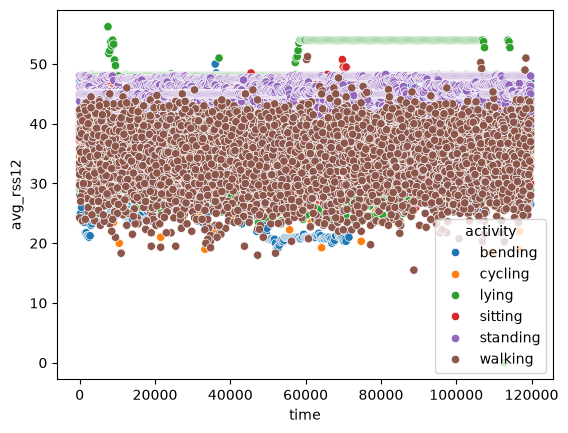

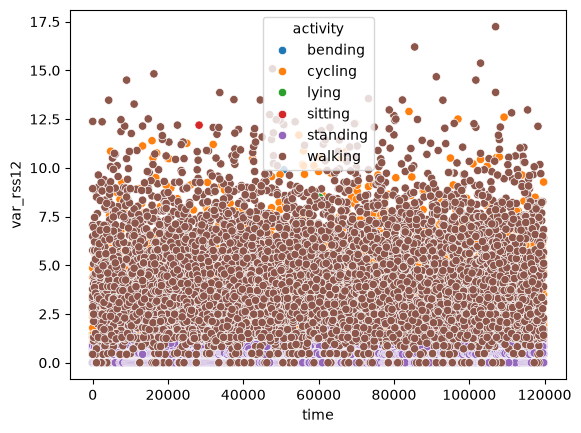

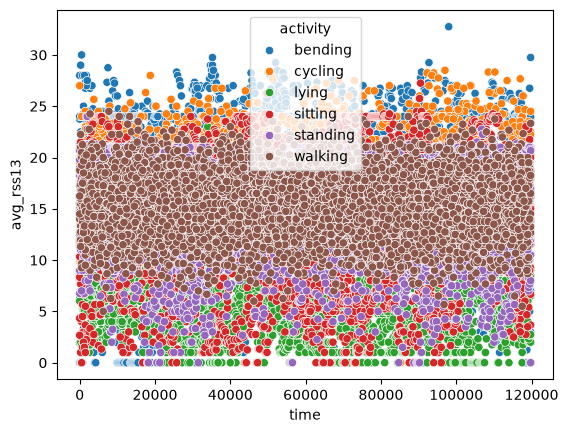

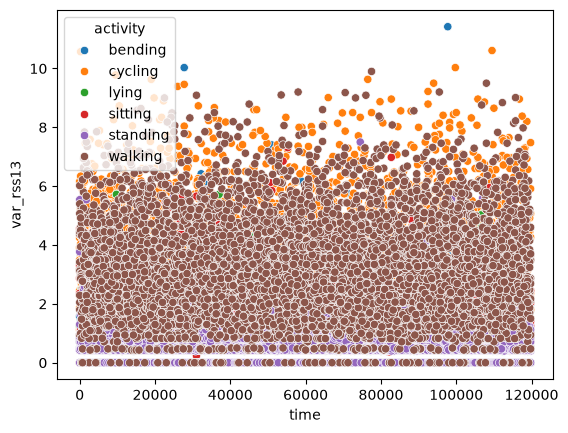

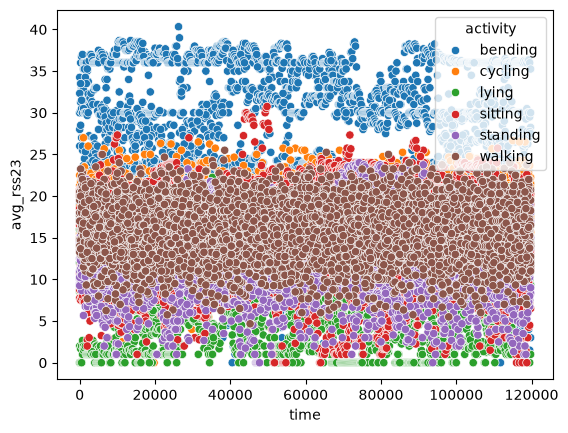

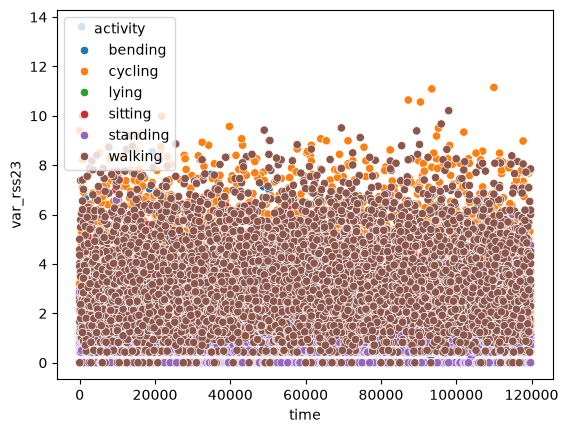

In [10]:
for feature in training_data.drop(['time', 'is_training_data', 'instance', 'activity'], axis=1).columns:
    sns.scatterplot(training_data, x='time', y=feature, hue='activity')
    plt.show()

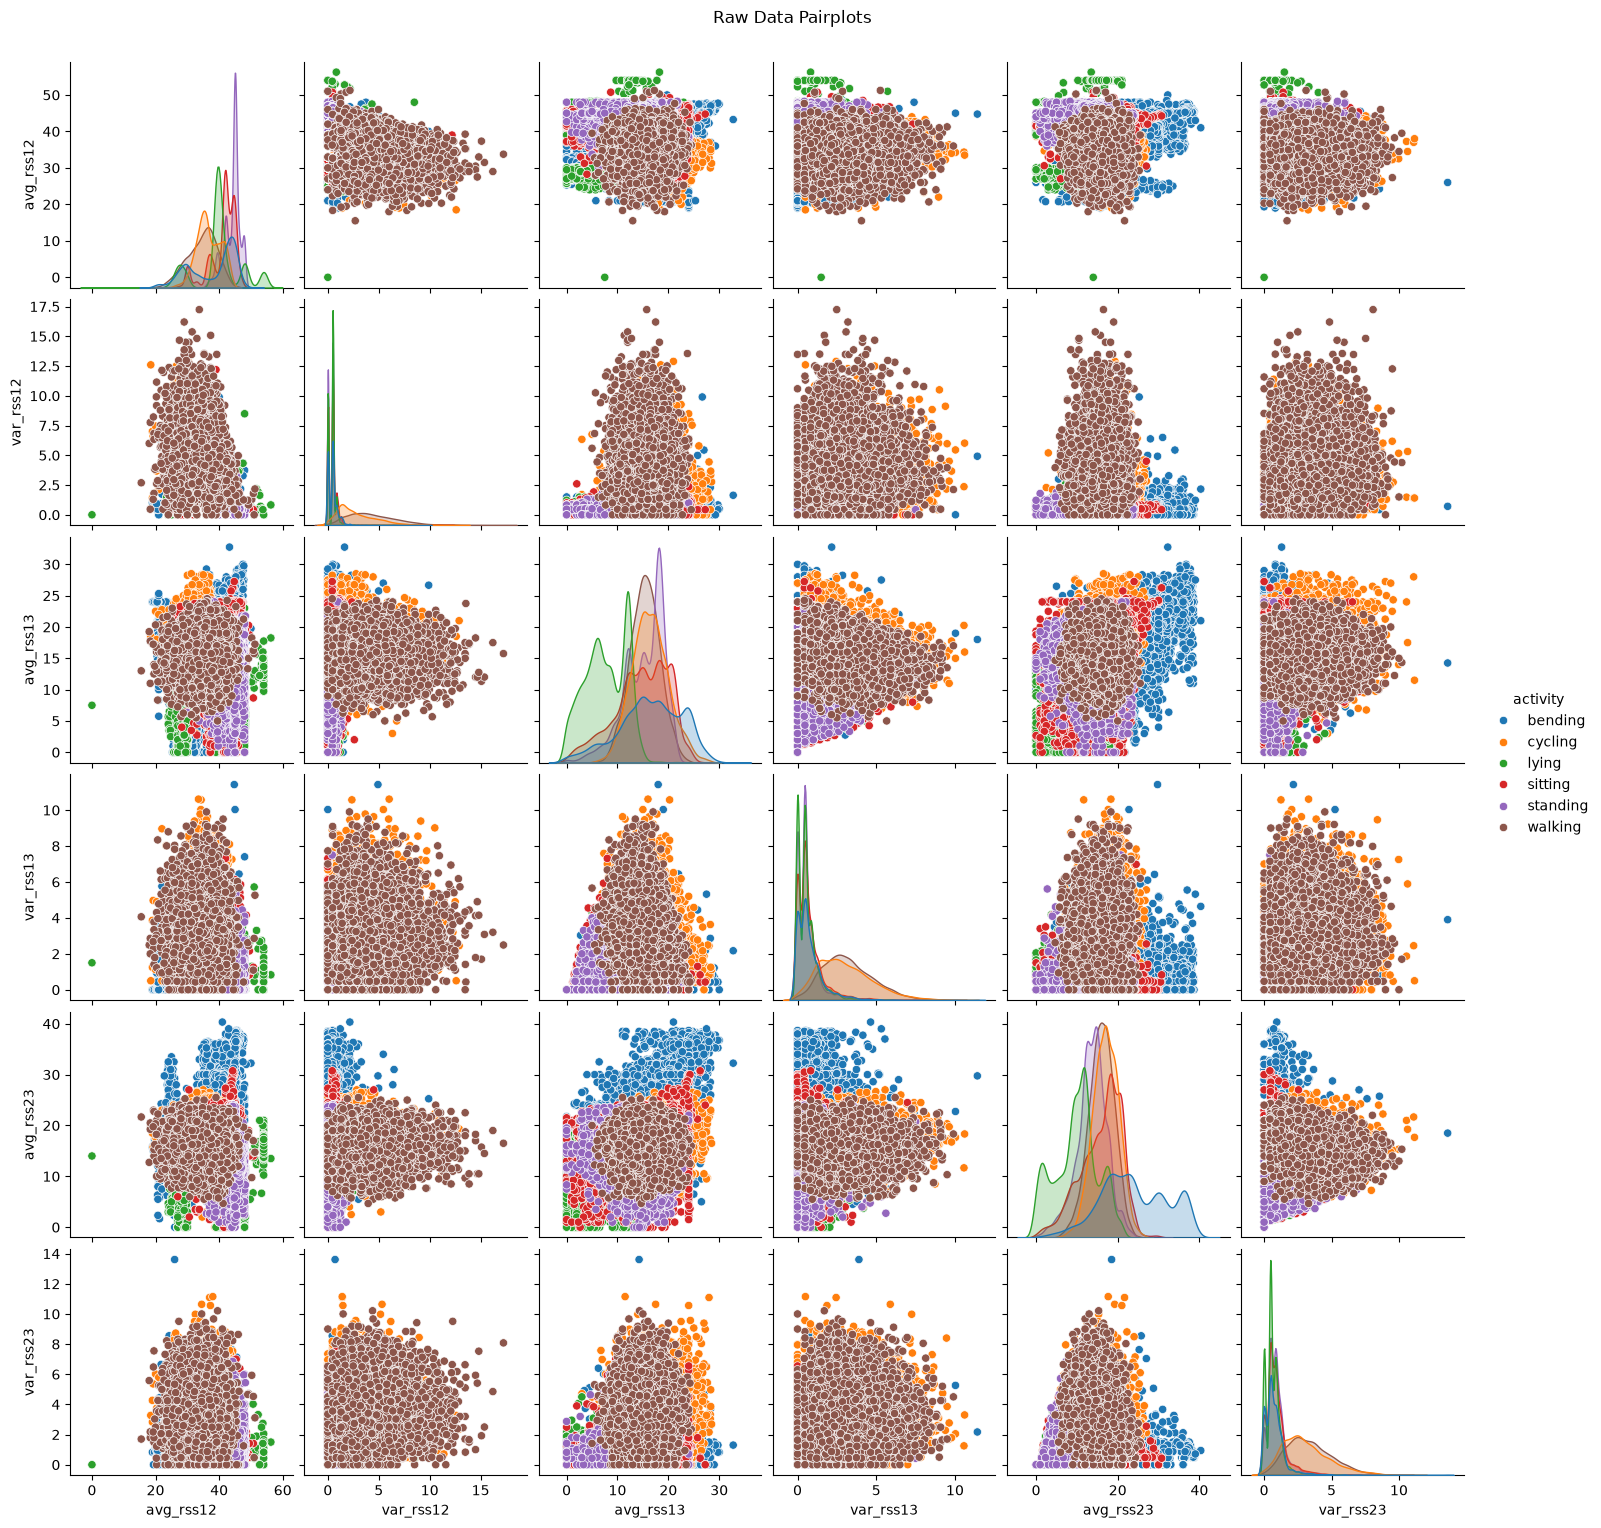

In [11]:
grid = sns.pairplot(training_data.drop(['time', 'is_training_data', 'instance'], axis=1), hue='activity')
grid.figure.suptitle('Raw Data Pairplots', y=1.02)
plt.show()

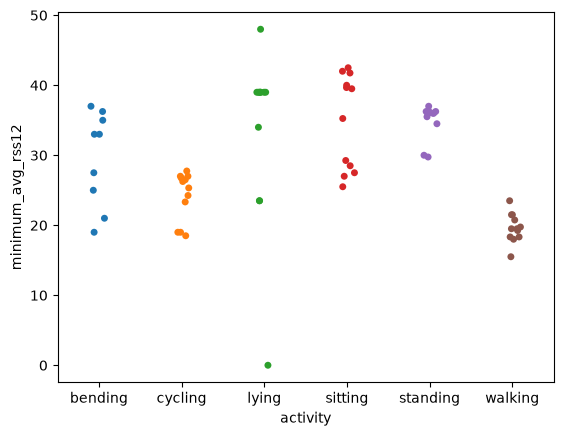

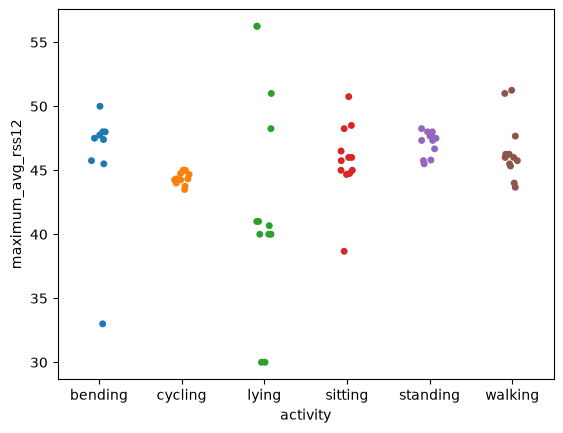

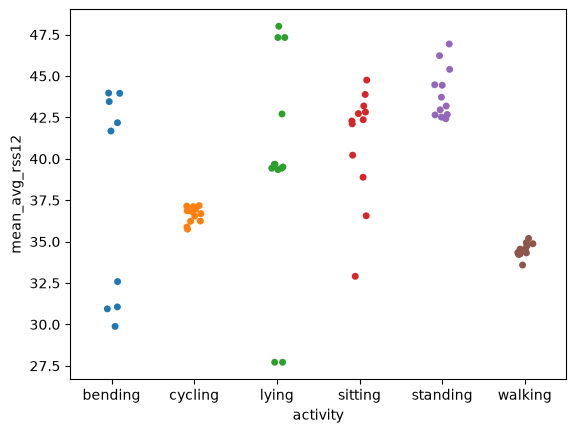

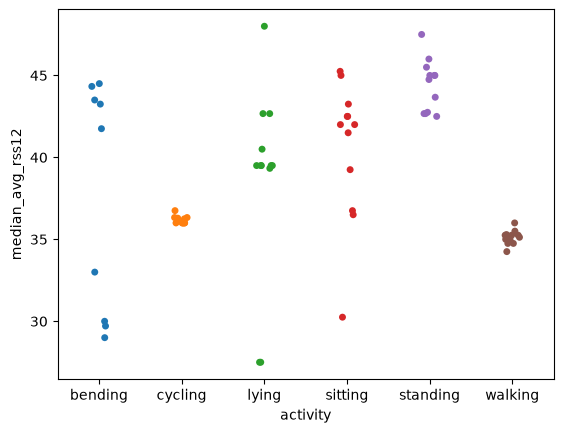

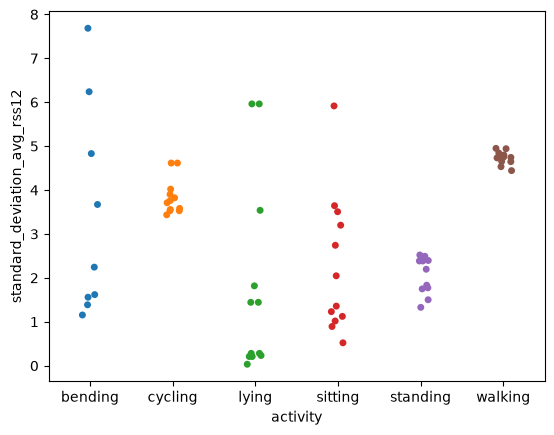

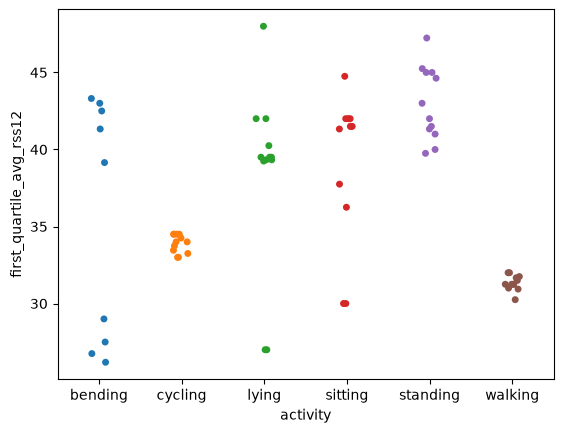

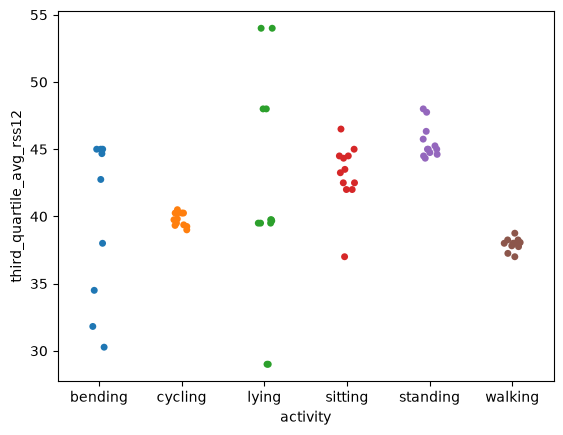

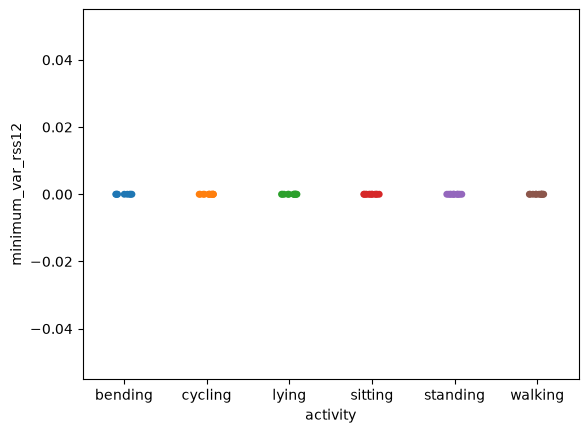

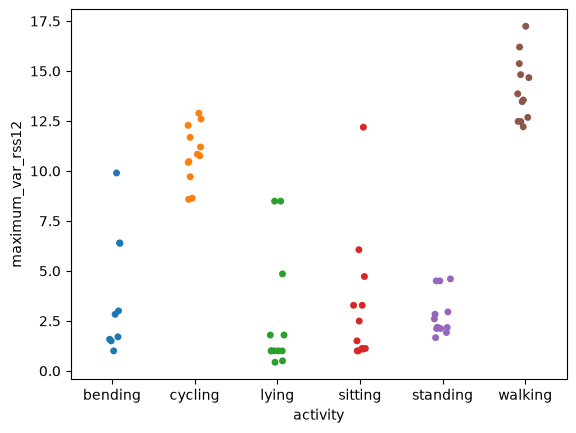

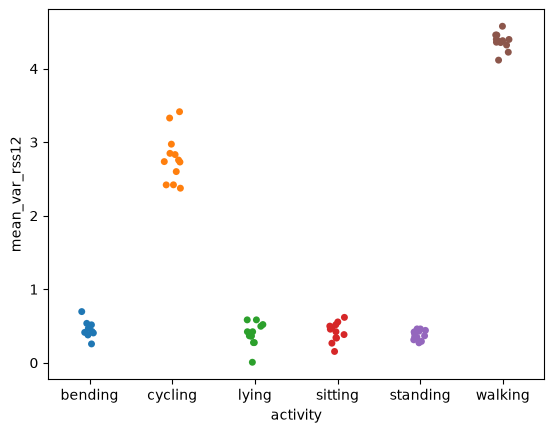

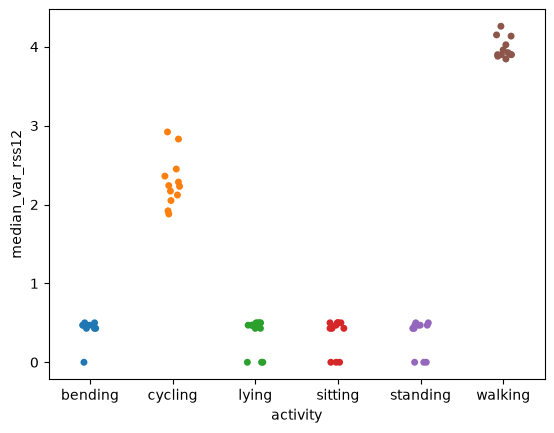

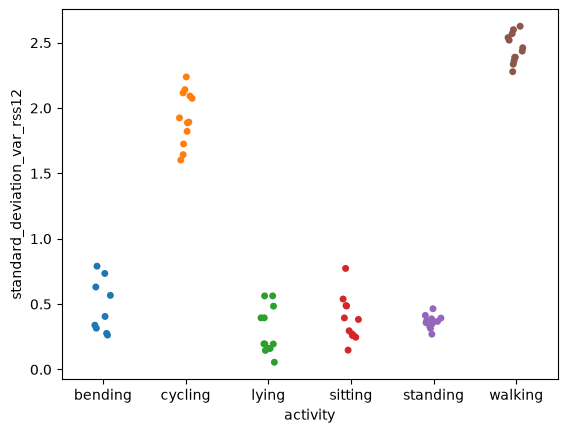

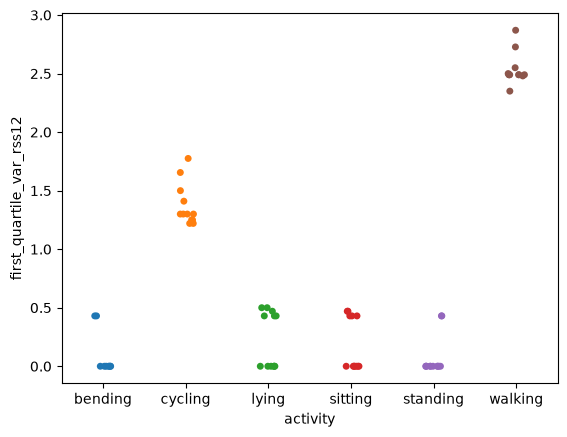

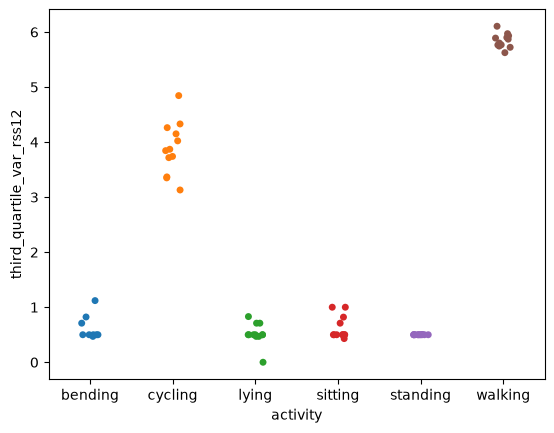

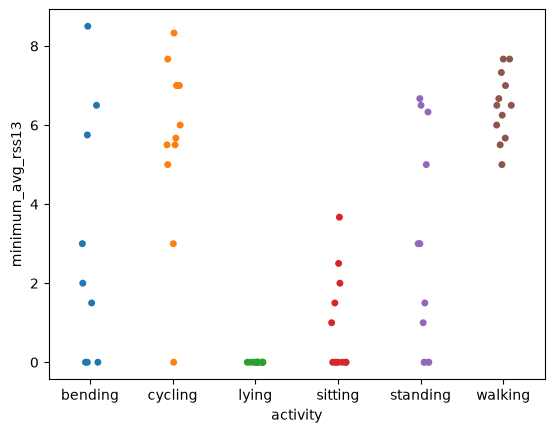

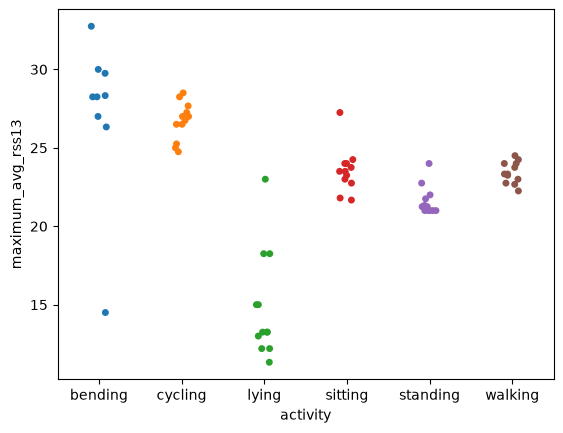

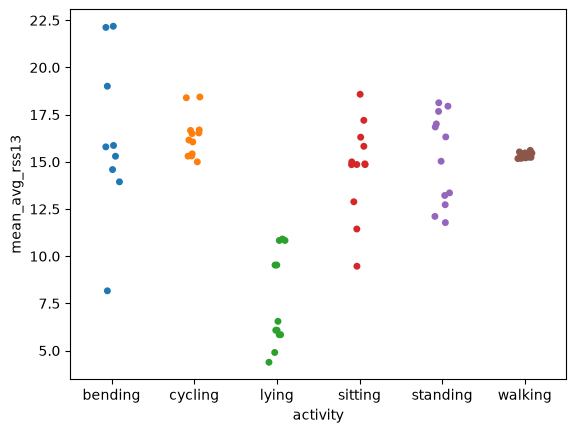

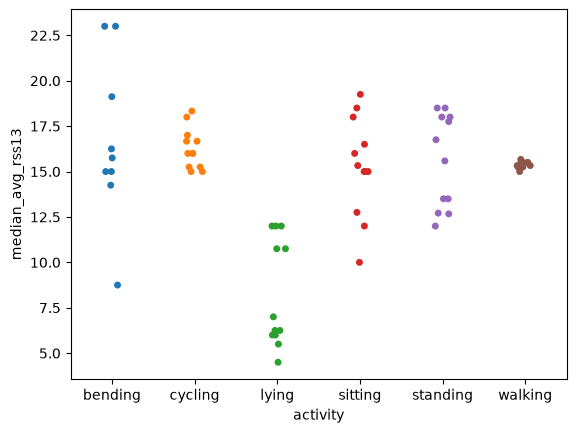

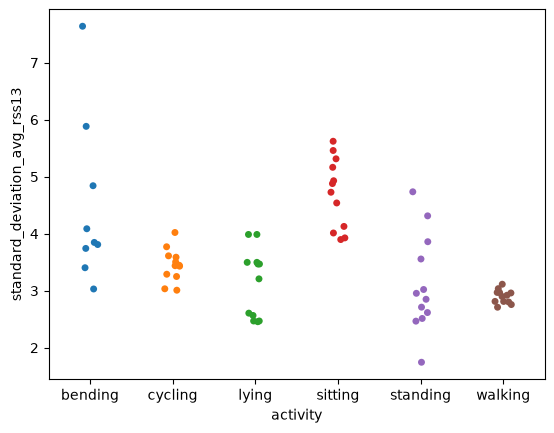

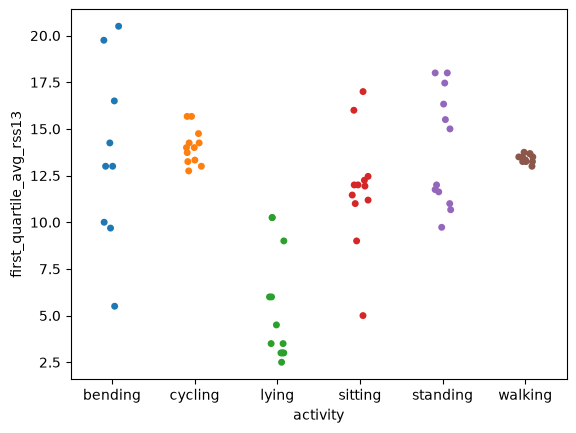

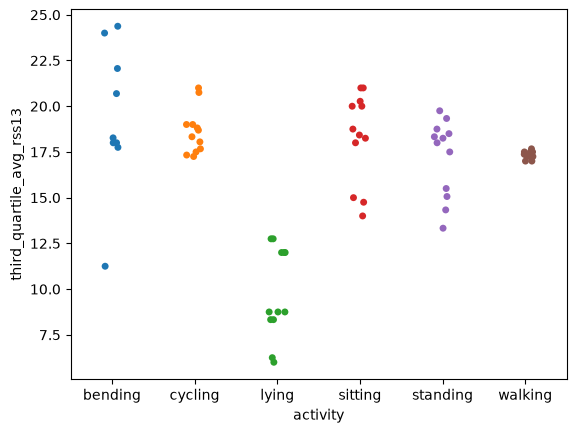

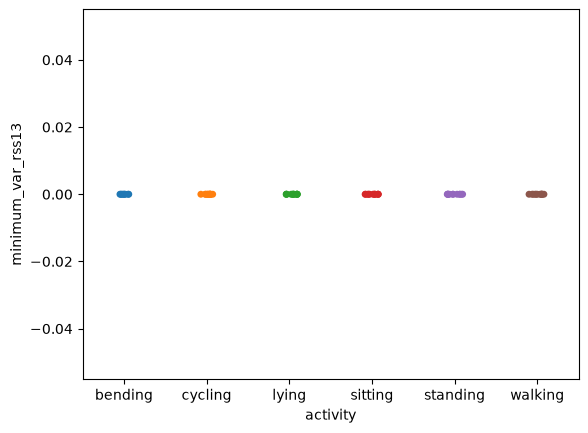

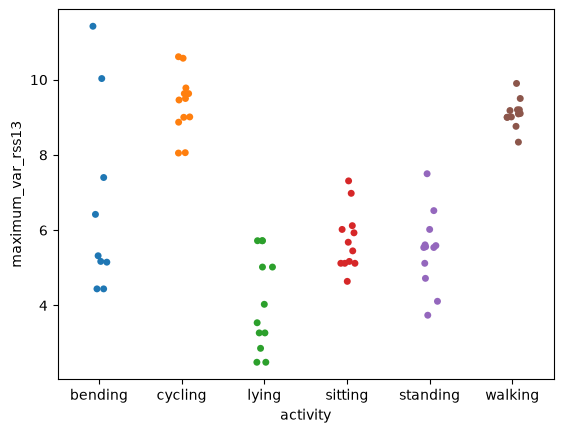

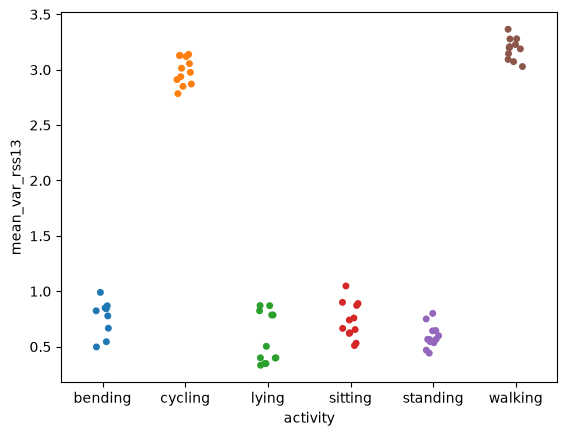

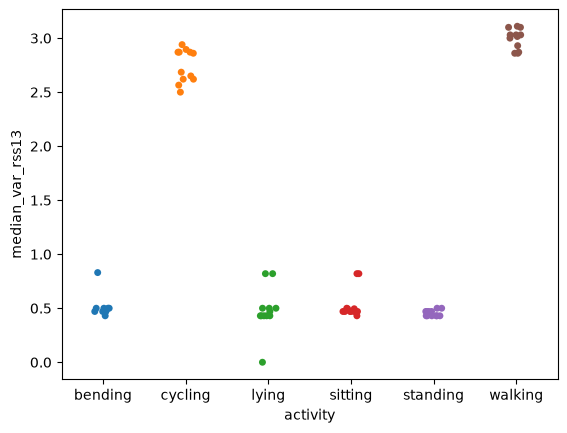

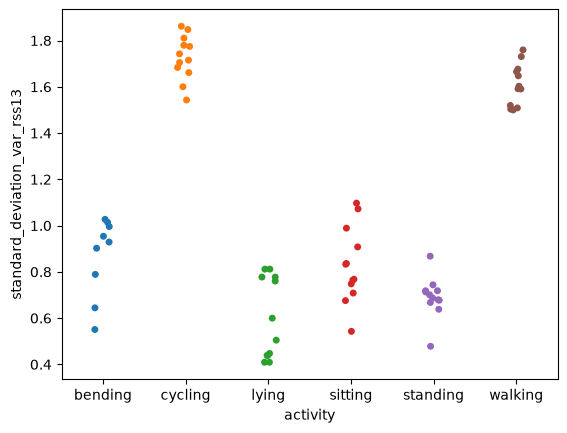

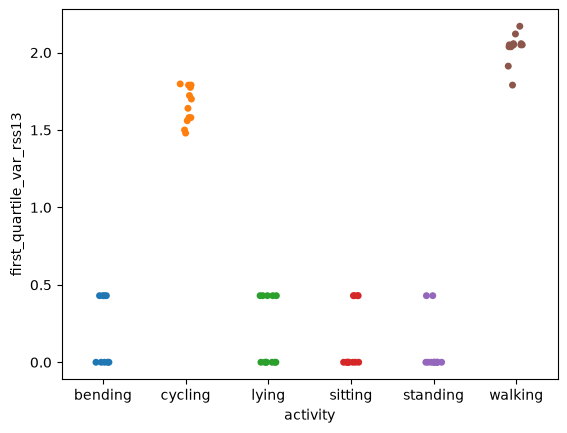

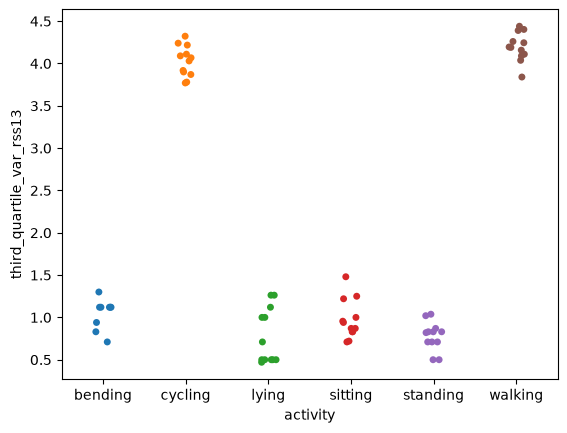

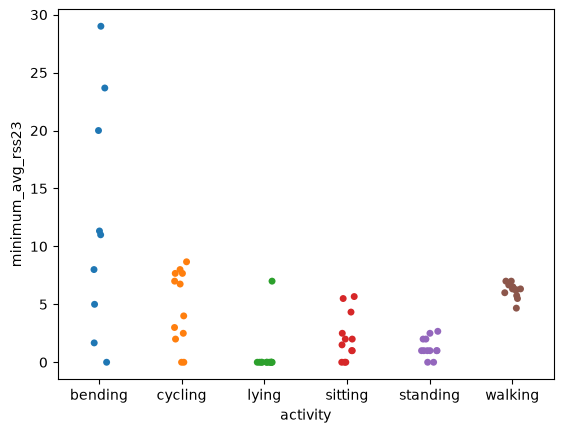

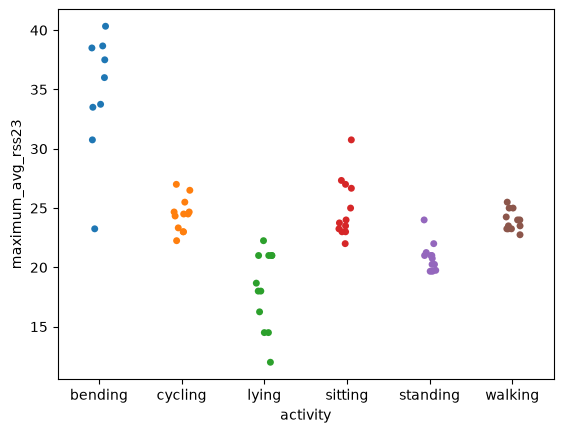

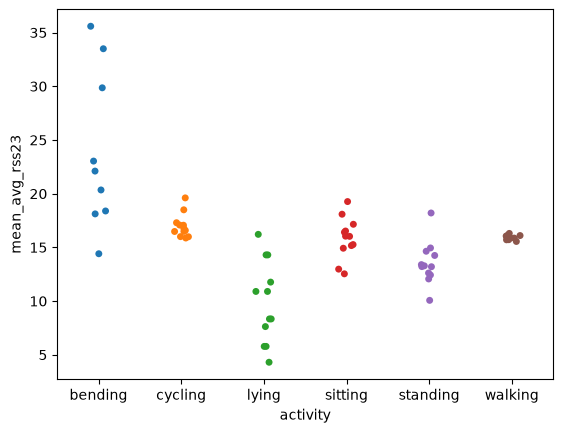

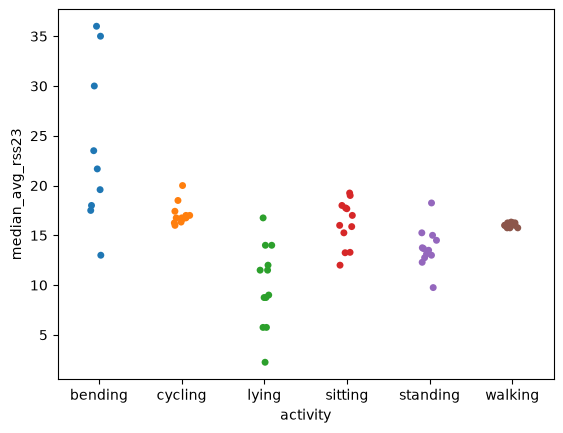

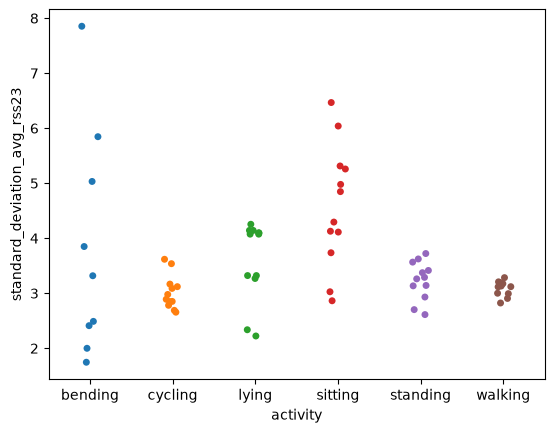

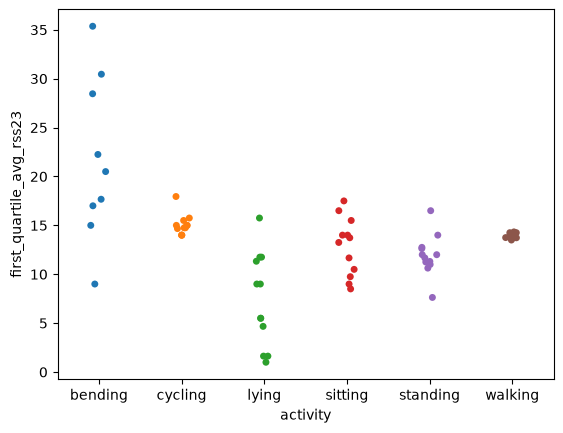

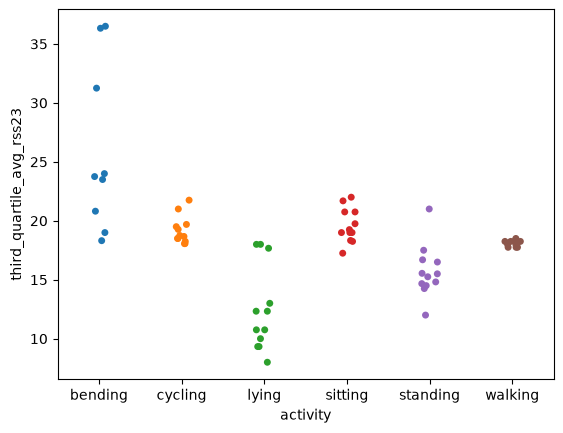

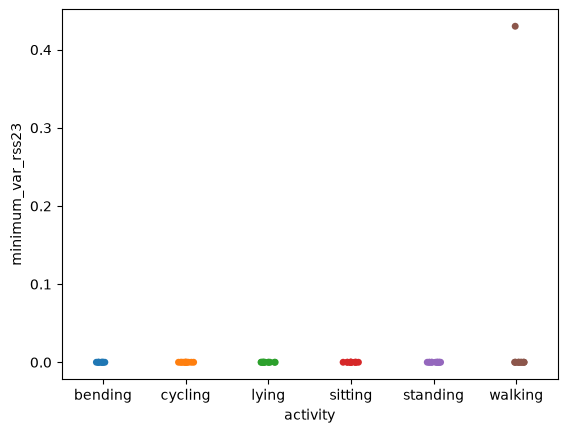

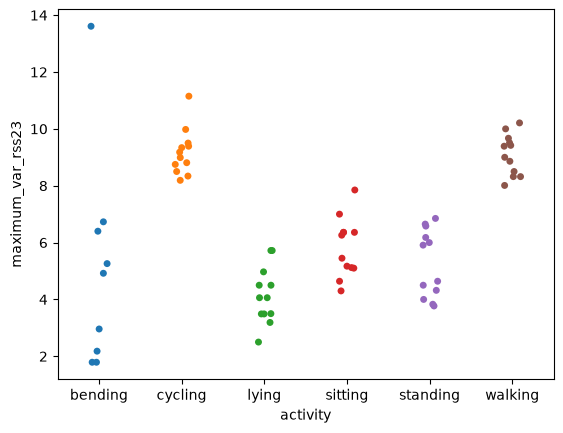

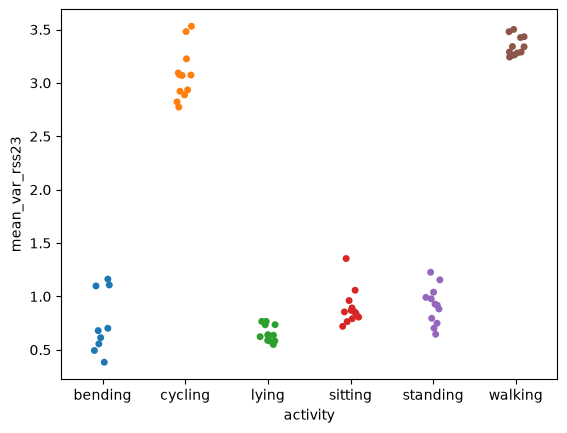

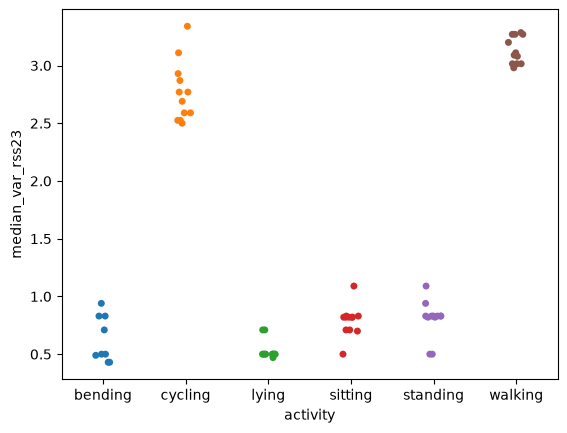

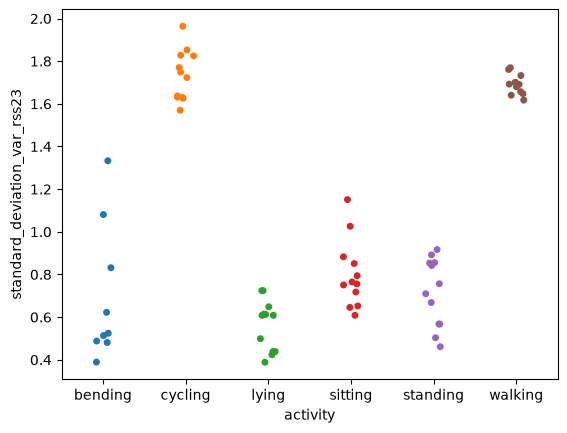

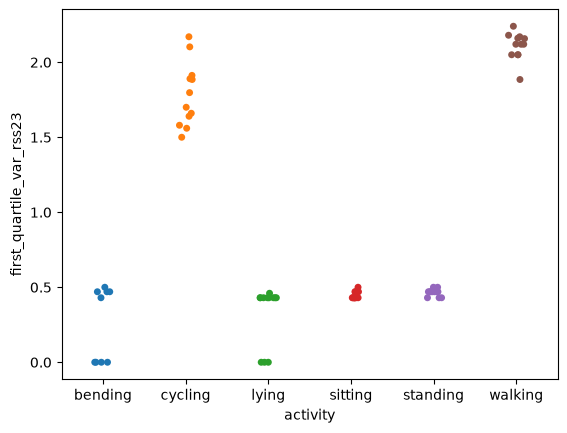

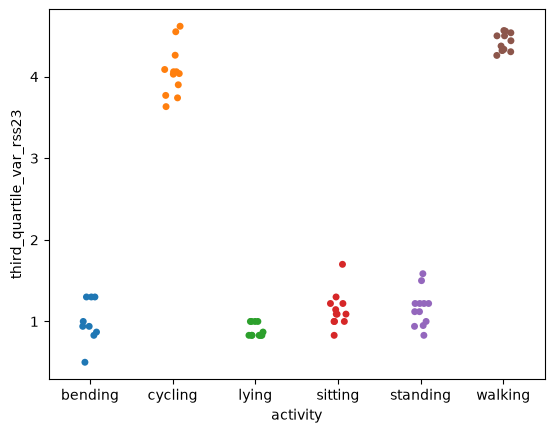

In [12]:
for feature in extracted_training_data.drop(['is_training_data', 'instance', 'activity'], axis=1).columns:
    sns.stripplot(extracted_training_data, x='activity', y=feature, hue='activity')
    plt.show()

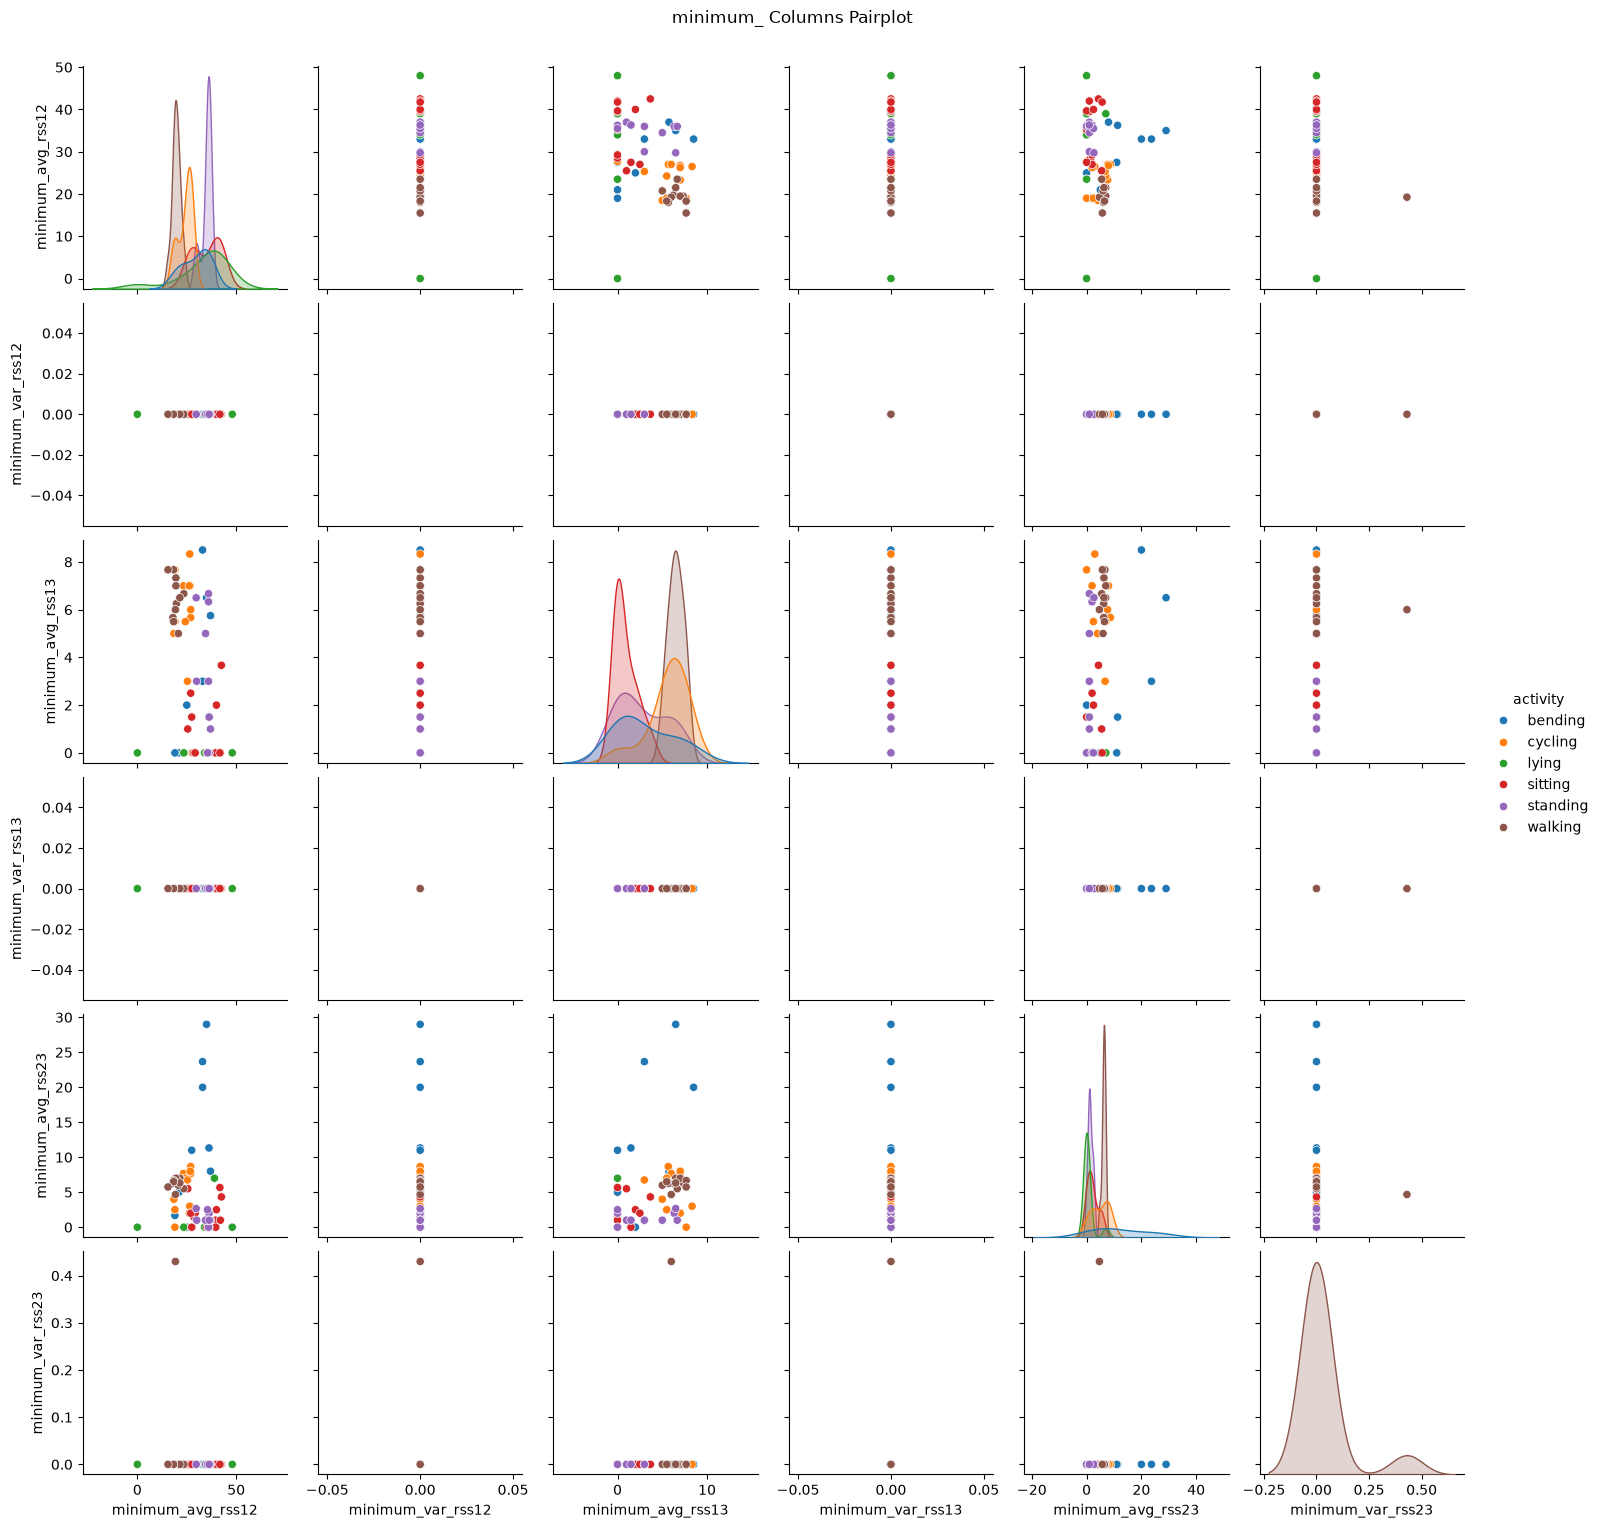

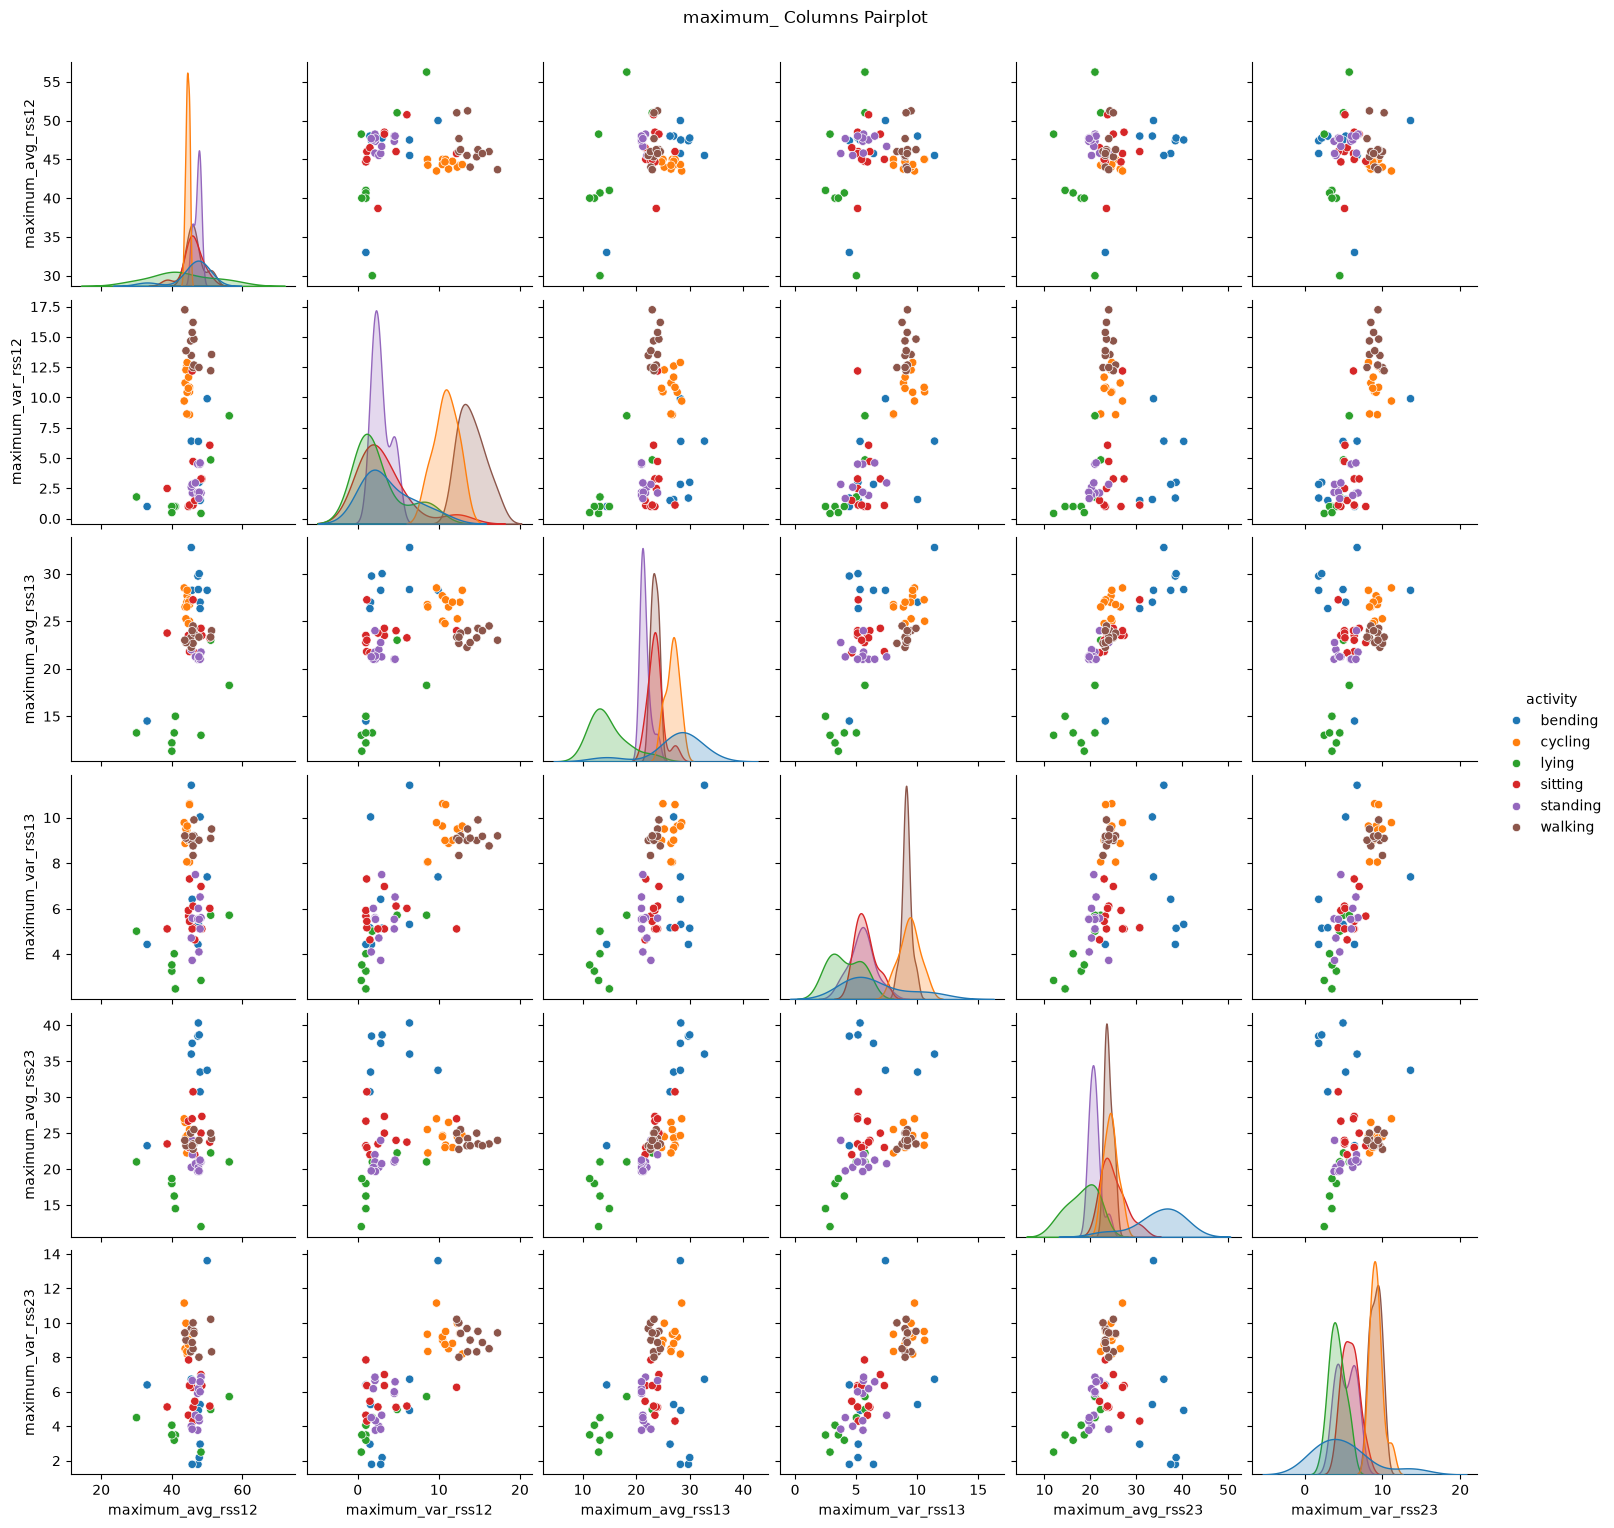

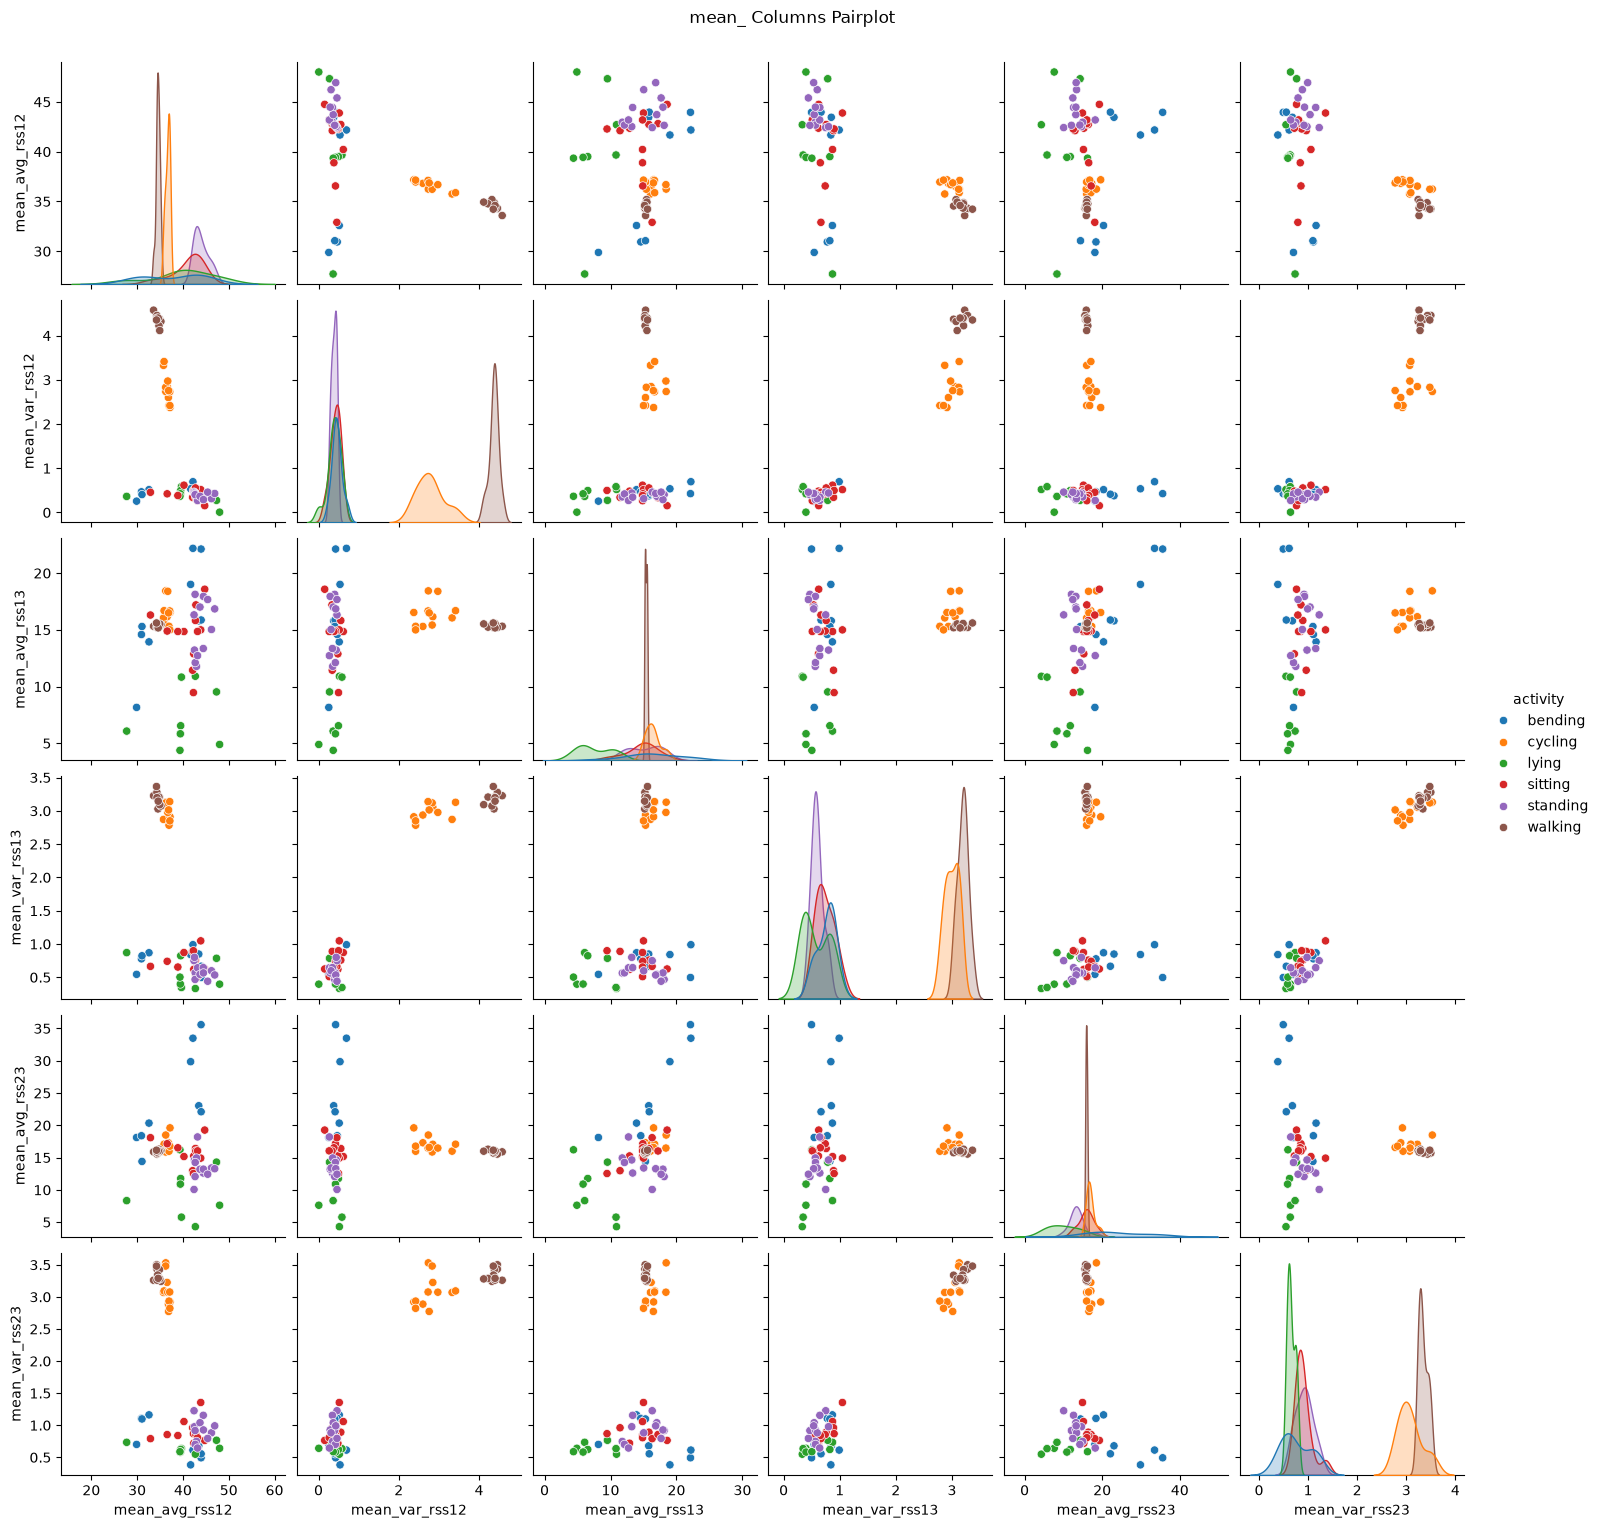

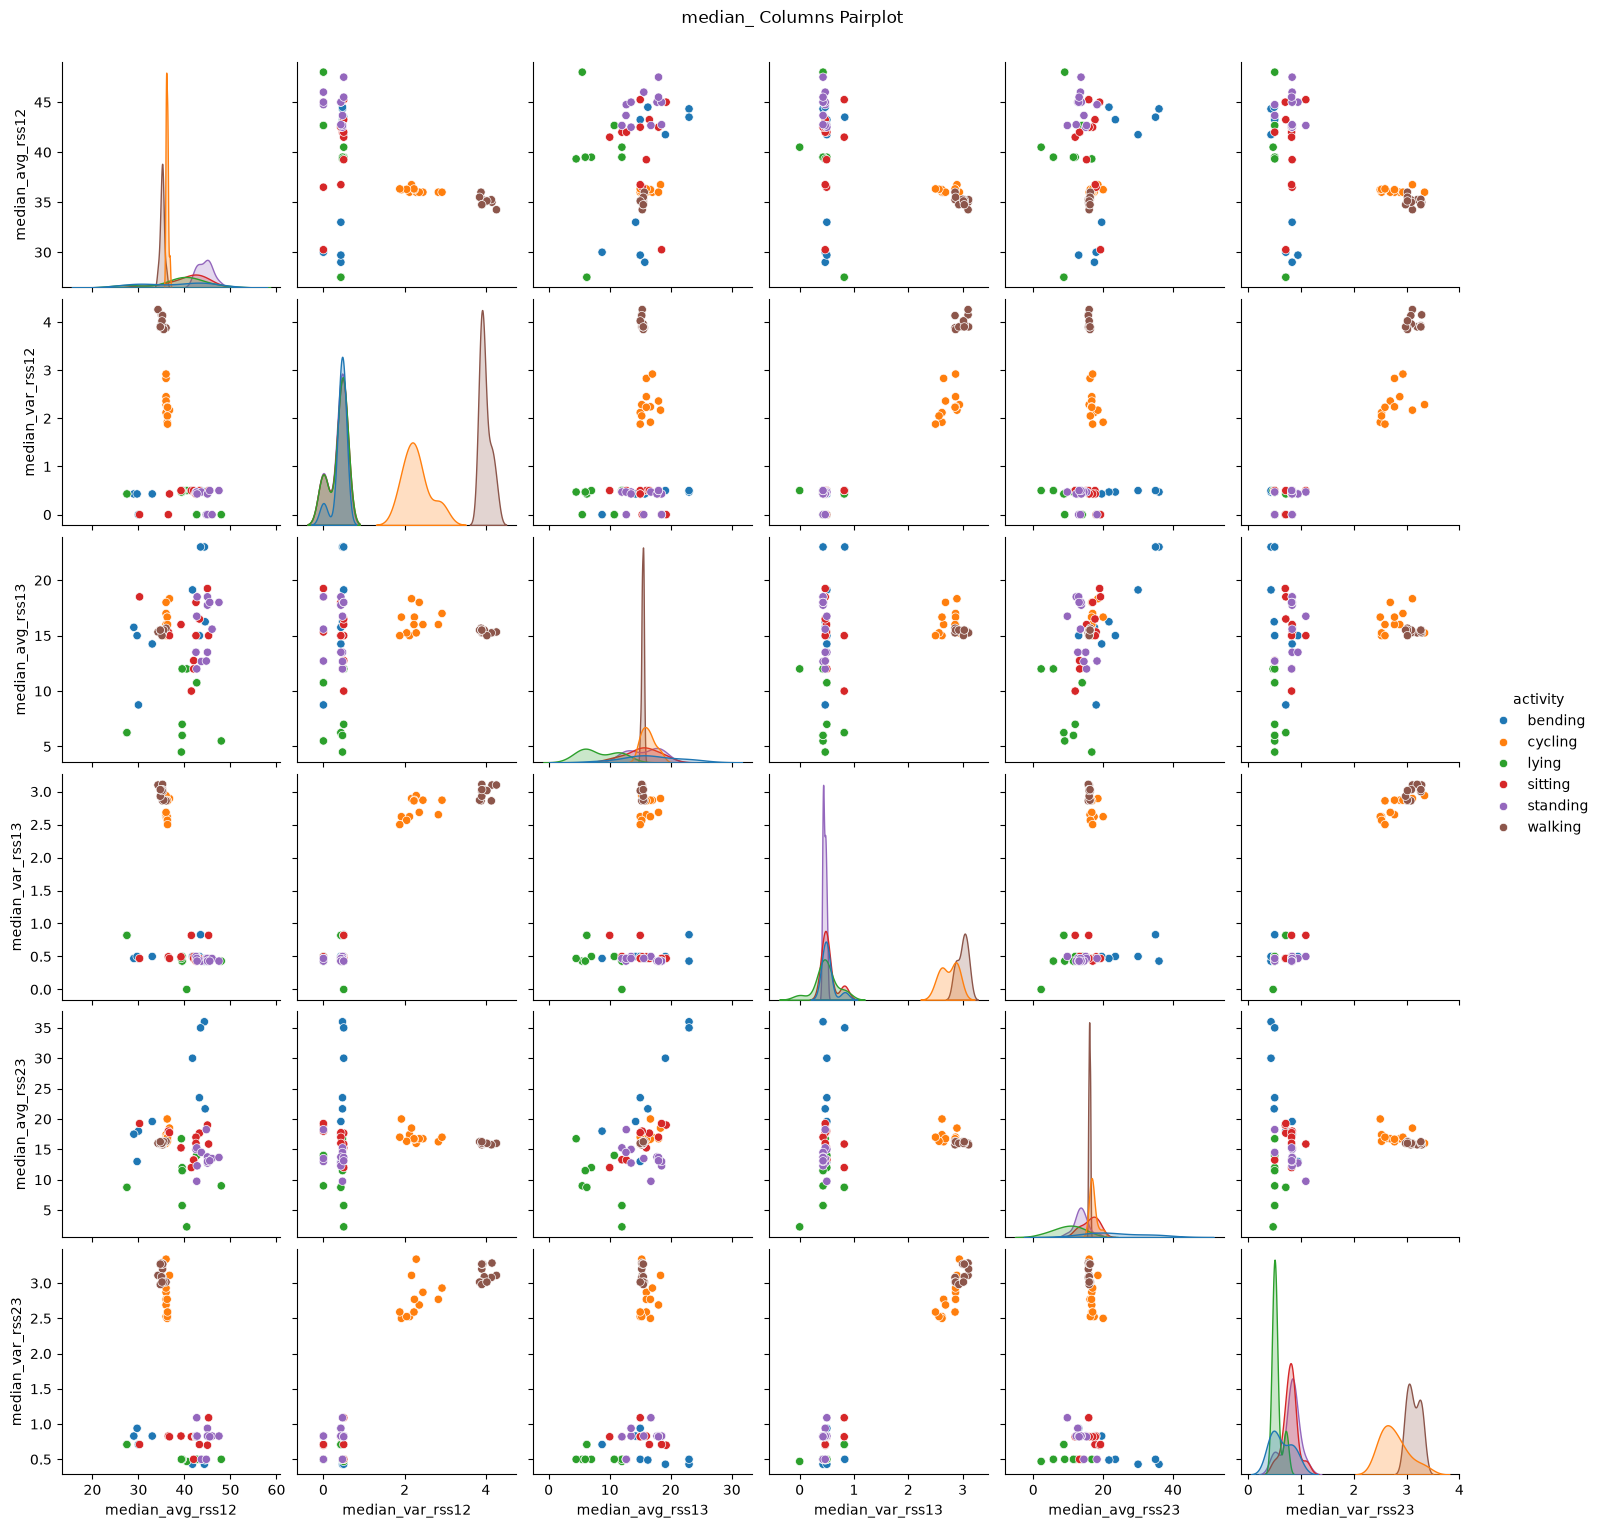

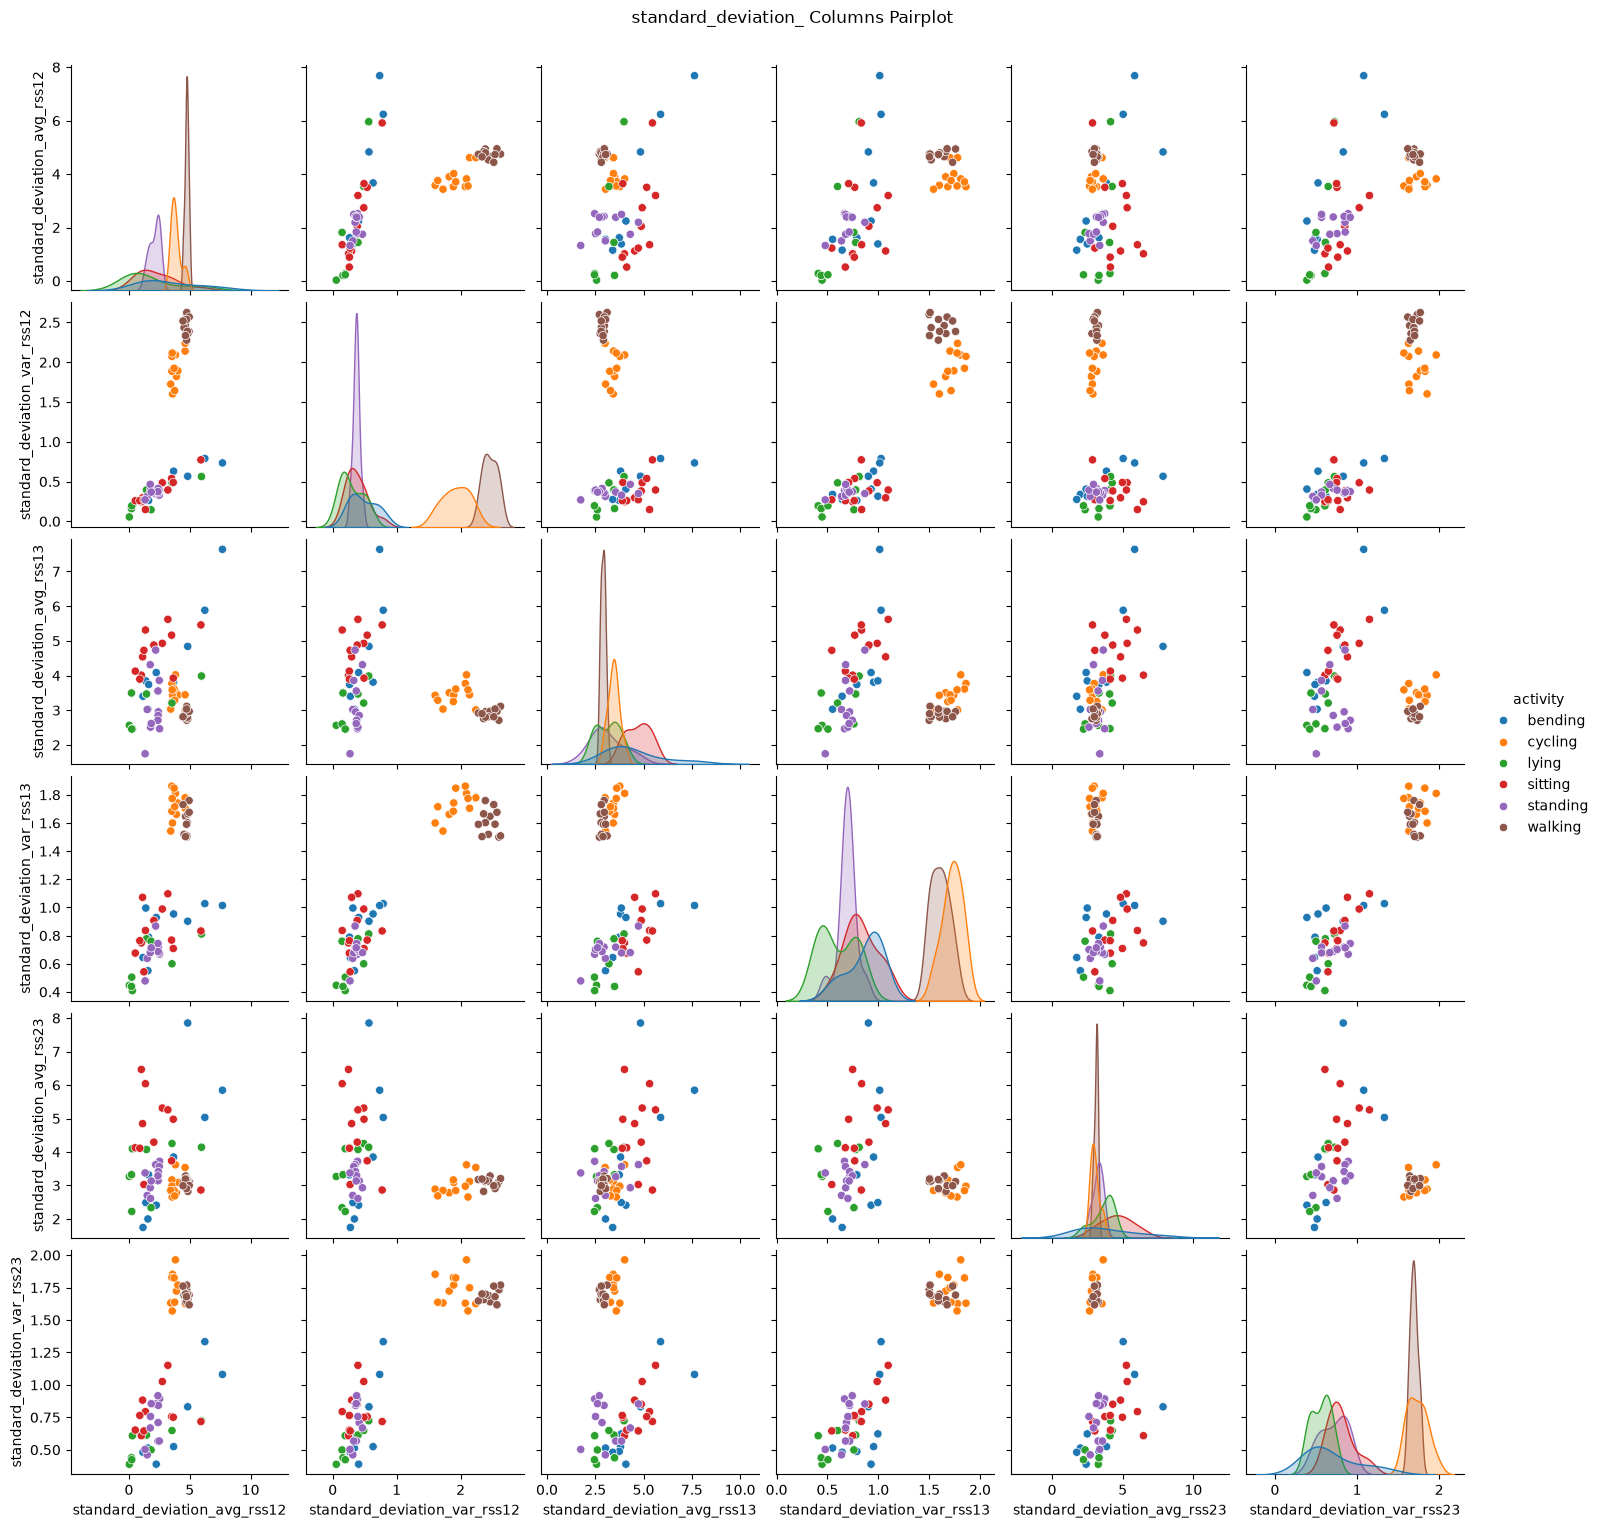

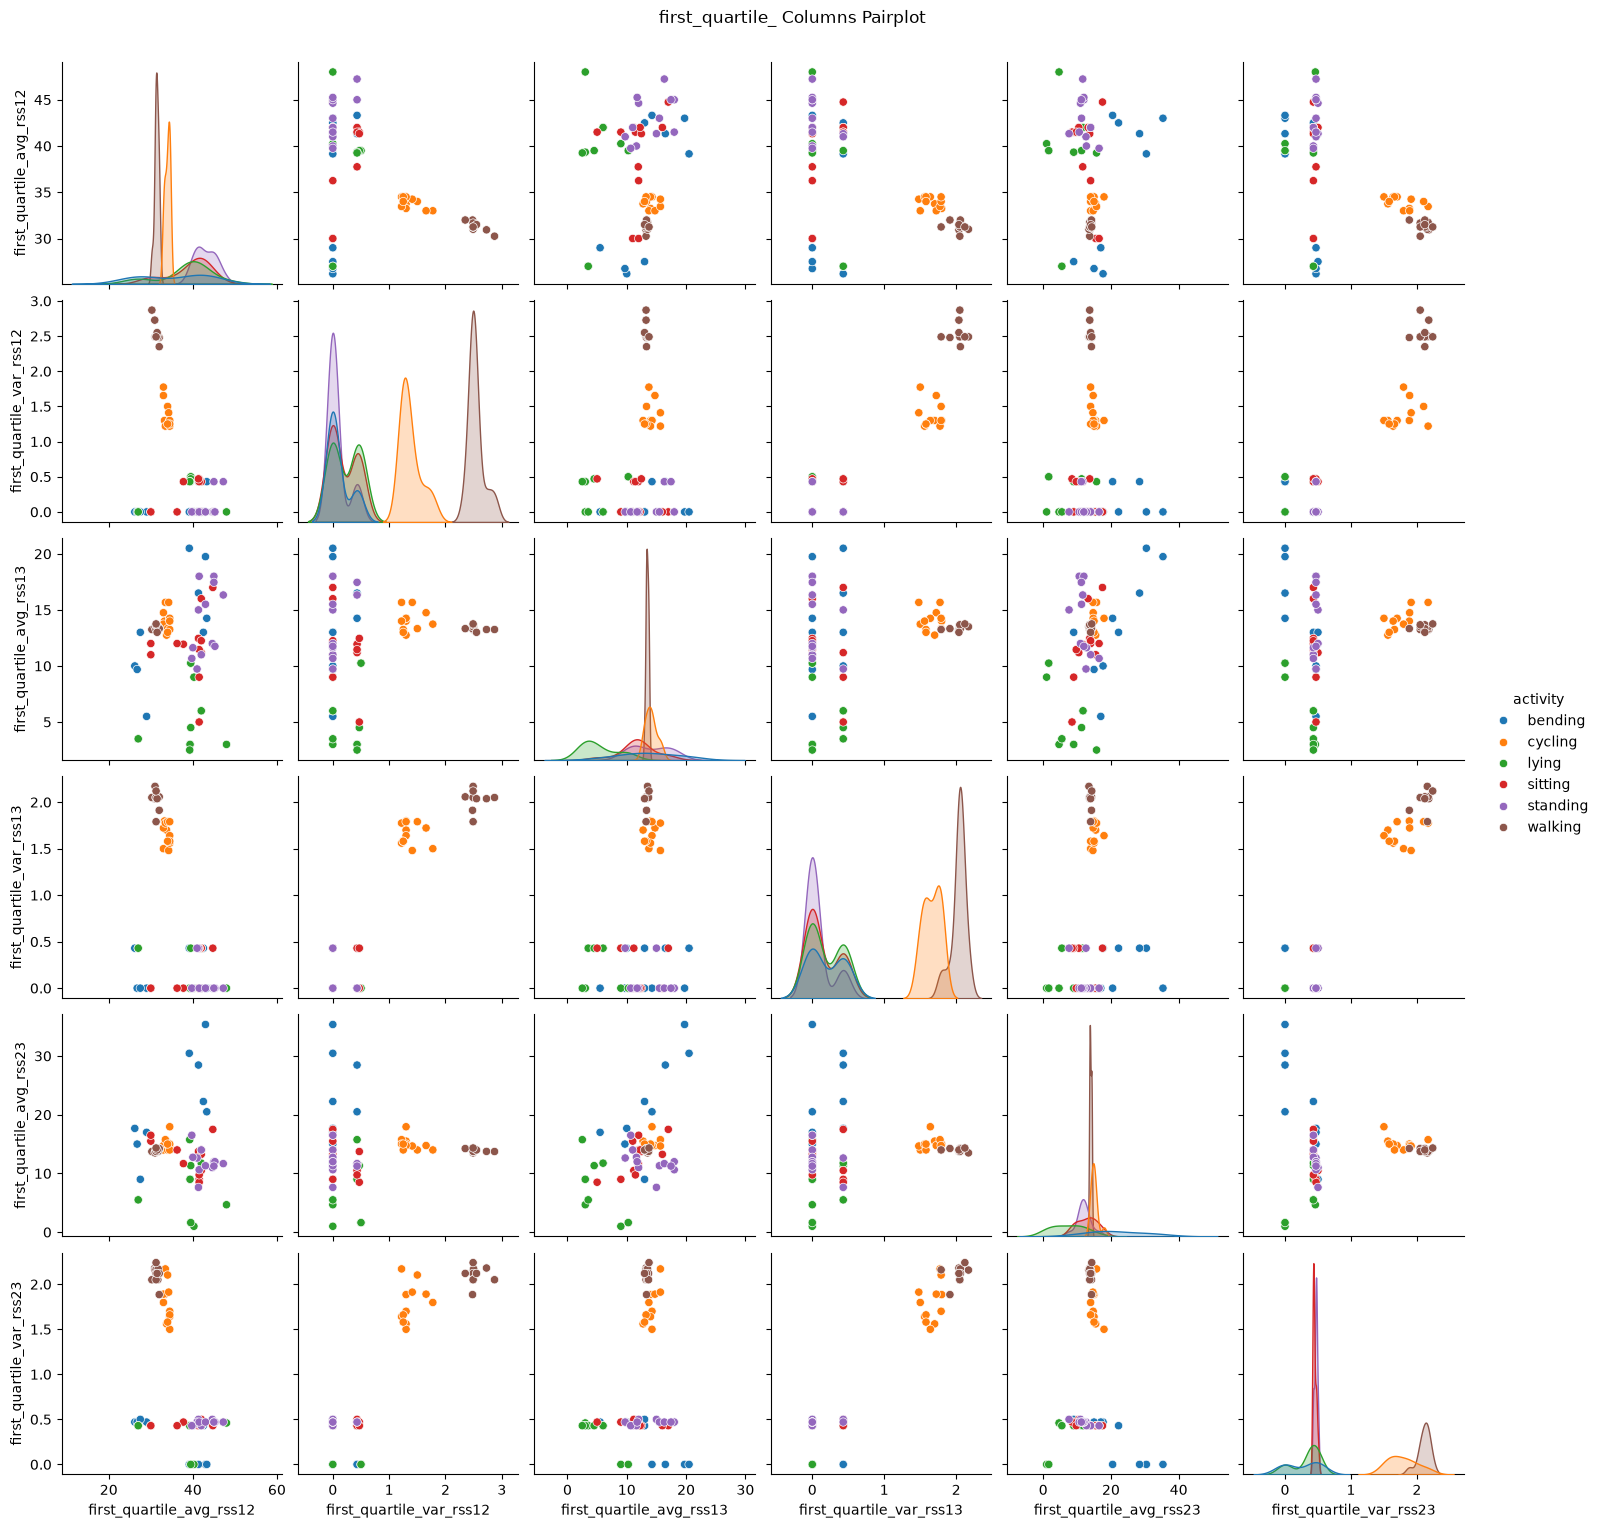

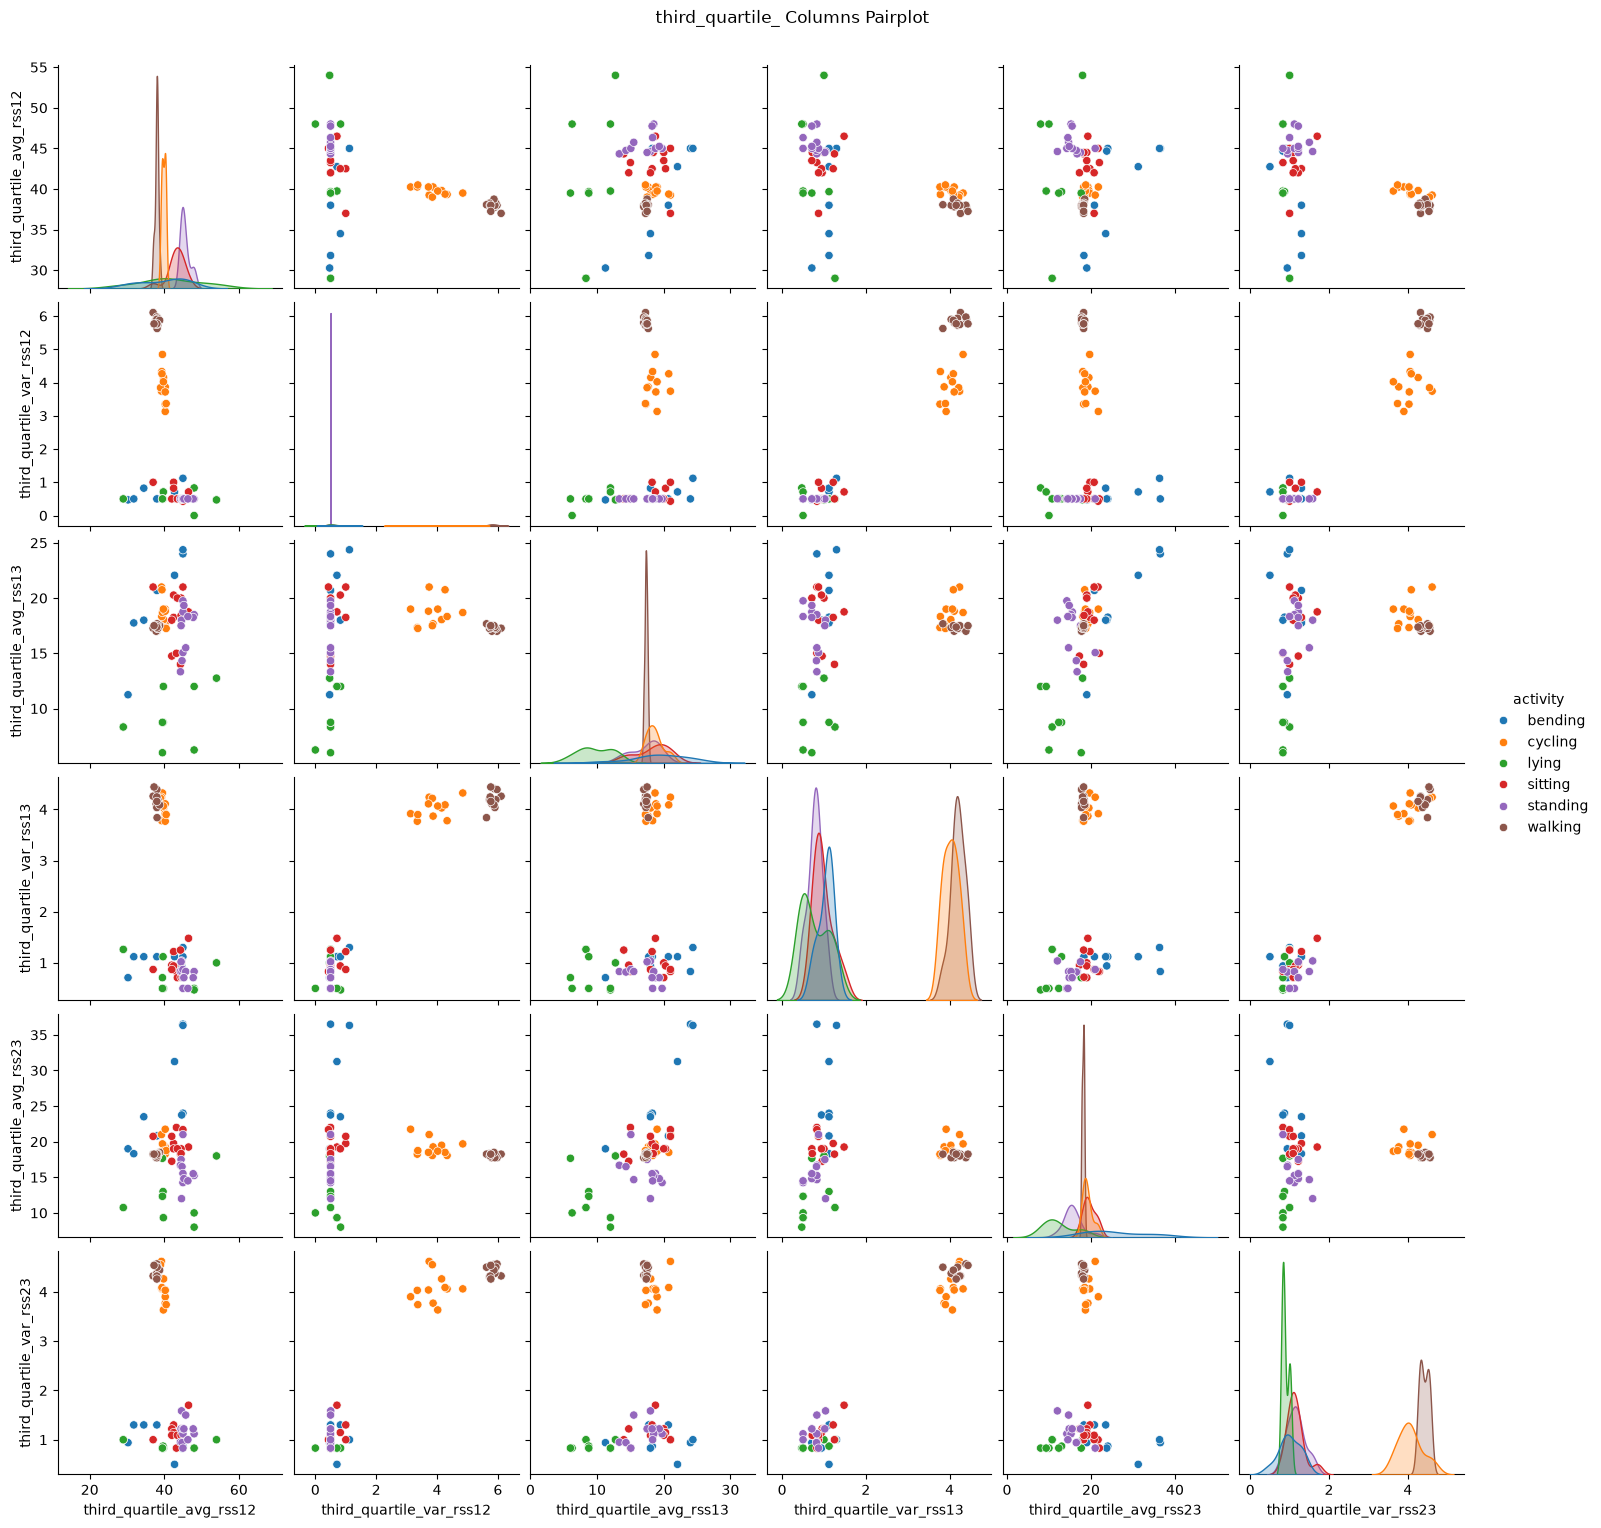

In [13]:
column_prefixes = ['minimum_', 'maximum_', 'mean_', 'median_', 'standard_deviation_', 'first_quartile_', 'third_quartile_']
for column_prefix in column_prefixes:
    prefixed_columns = [column for column in extracted_training_data.columns if column.startswith(column_prefix)]
    grid = sns.pairplot(extracted_training_data, vars=prefixed_columns, hue='activity')
    grid.figure.suptitle(f'{column_prefix} Columns Pairplot', y=1.02)
    plt.show()

The three statistical measures that I chose based on intuition, strip and pair plots, and what they represent are **max, mean, and standard deviation**. The strip and pair plots provide visual support to determine which statistics offer clearly separated clusters that tie back to specific activities. Mean is a logical first choice, and the visuals support this. Based on the plots, the groupings appear clearer than median. To capture the extremes, minimum and maximum are the logical choices. However, several of the minimum extracted features (e.g., `minimum_var_rss12`) are zeroes, which provides no separation. Maximums provide more information and clearer boundaries. Standard deviation captures how much the feature data can vary, which provides a different lens than max and mean. Therefore, these three statistics cover a wide scope with minimal overlap in terms of information gained.

## 2. ISLR 3.7.4

### (a) Linear Train

We would expect the training residual sum of squares for the cubic regression to be less than or equal to the linear regression. Even though the true f(x) is linear, the cubic regression can simply zero out the nonlinear betas to match the linear model. In addition, the cubic regression can overfit the linear function combined with the noise (i.e., irreducible error).

### (b) Linear Test

We would expect the test residual sum of squares to be lower for the linear regression than the cubic regression. While the training error is likely lower for cubic, this is due to overfitting. It would perform worse on unseen test data due to variance.

### (c) Not Linear Train

We would expect the training residual sum of squares for the cubic regression to be less than the linear regression. While we don't know how far it is from linear, the lower bias of the cubic regression will allow the model to fit the training data better than a linear one.

### (d) Not Linear Testing

We don't have enough information to tell. The answer depends on how far away from linear the true f(x) is. If very close to linear, the linear regression could win based on lower variance. If highly nonlinear, the cubic regression would almost certainly win based on lower bias.